# Dự đoán Kết quả Trận đấu (Thắng/Hòa/Thua) với XGBoost, MLflow và SHAP

In [1]:
# 1. Cài đặt các thư viện cần thiết
!pip install -q mlflow==3.16.1 xgboost shap duckdb pysocks


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.0/50.0 kB 2.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.9/50.9 kB 5.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.7/11.7 MB 53.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.8/3.8 MB 46.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 39.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 14.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.8/148.8 kB 6.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 5.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 228.4/228.4 kB 9.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 136.5/136.5 kB 9.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.7/148.7 kB 6.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.

In [2]:
# Upload file colab_utils.py từ máy tính
from google.colab import files
uploaded = files.upload()
print("Uploaded:", list(uploaded.keys()))

import importlib
import colab_utils
importlib.invalidate_caches()
importlib.reload(colab_utils)
print("File đang dùng:", colab_utils.__file__)


Saving colab_utils.py to colab_utils.py
Uploaded: ['colab_utils.py']
File đang dùng: /content/colab_utils.py


In [4]:
import colab_utils
from google.colab import userdata

colab_utils.install_tailscale()

status = colab_utils.setup_tailscale()
print("Connected check:", colab_utils.tailscale_is_connected())


Đang cài Tailscale...
Cài Tailscale thành công.
100.82.94.58     google-colab-5  taohshsh1303@  linux    -                           
100.116.34.36    ai-lab          taohshsh1303@  linux    -                           
100.118.178.119  baongoc         taohshsh1303@  windows  -                           
100.110.38.52    google-colab-1  taohshsh1303@  linux    offline, last seen 10h ago  
100.115.170.30   google-colab-2  taohshsh1303@  linux    offline, last seen 1h ago   
100.94.113.41    google-colab-3  taohshsh1303@  linux    offline, last seen 1h ago   
100.98.11.71     google-colab-4  taohshsh1303@  linux    offline, last seen 3m ago   
100.66.218.91    google-colab    taohshsh1303@  linux    offline, last seen 11h ago  
100.70.174.90    vmlab1          taohshsh1303@  linux    -
HTTP proxy: http://localhost:1056
SOCKS5 proxy: socks5://localhost:1055
Connected check: True


In [5]:
MLFLOW_URI = "http://100.116.34.36:8080"
EXPERIMENT_NAME = "Match-Prediction-XGBoost"

colab_utils.setup_mlflow(
    server_uri=MLFLOW_URI,
    experiment=EXPERIMENT_NAME,
)

MLflow server phản hồi HTTP 200: http://100.116.34.36:8080
MLflow tracking URI: http://100.116.34.36:8080
Experiment: Match-Prediction-XGBoost


'http://100.116.34.36:8080'

In [6]:
import duckdb
import pandas as pd
from google.colab import userdata

def load_data_from_minio():
    print("Kết nối MinIO...")

    con = duckdb.connect(":memory:")
    con.execute("INSTALL httpfs")
    con.execute("LOAD httpfs")

    minio_endpoint = "20.41.113.183:9000"
    minio_ak = userdata.get("MINIO_ACCESS_KEY")
    minio_sk = userdata.get("MINIO_SECRET_KEY")

    if not minio_ak or not minio_sk:
        raise ValueError("Thiếu MinIO credentials trong Colab Secrets")

    con.execute(f"""
        CREATE OR REPLACE SECRET minio_secret (
            TYPE S3,
            KEY_ID '{minio_ak.replace("'", "''")}',
            SECRET '{minio_sk.replace("'", "''")}',
            ENDPOINT '{minio_endpoint}',
            URL_STYLE 'path',
            USE_SSL false
        )
    """)

    path = "s3://football-lake/dwh/mart_ml_match_features.parquet"

    print(f"Đang tải: {path}")
    df = con.execute(
        f"SELECT * FROM read_parquet('{path}')"
    ).df()

    con.close()
    return df

df = load_data_from_minio()

print("Kích thước dữ liệu:", df.shape)
display(df.head())

Kết nối MinIO...
Đang tải: s3://football-lake/dwh/mart_ml_match_features.parquet
Kích thước dữ liệu: (25560, 214)


,match_key,competition_key,season,match_date,kickoff_utc,home_key,away_key,fdo_match_id,understat_match_id,af_fixture_id,...,y_us_xg_p_draw,y_us_xg_p_away,y_home_xg,y_away_xg,y_home_shots,y_away_shots,y_home_shots_target,y_away_shots_target,y_total_corners,y_total_cards
0,0c754c91c82b09bcbb4a2c7e24f65d25,CHAMPIONSHIP,2023,2023-09-23,2023-09-23 14:00:00,Plymouth,Norwich City,None,None,None,...,NaN,NaN,NaN,NaN,16,11,10,6,9,1
1,730a36a4f3b8d6884af048665295406f,CHAMPIONSHIP,2023,2023-10-24,2023-10-24 18:45:00,Swansea,Watford,None,None,None,...,NaN,NaN,NaN,NaN,9,12,3,5,10,3
2,e4680461ec08ce03e534d0e988fac9c7,CHAMPIONSHIP,2023,2023-10-28,2023-10-28 14:00:00,Middlesbrough,Stoke,None,None,None,...,NaN,NaN,NaN,NaN,9,13,3,6,12,4
3,44465f39f91fb89a3a9be84dba4587af,CHAMPIONSHIP,2023,2023-11-04,2023-11-04 15:00:00,West Brom,Hull City,None,None,None,...,NaN,NaN,NaN,NaN,10,9,5,4,3,2
4,cee639c1056ae158b36a3eb6b74cd912,CHAMPIONSHIP,2023,2023-11-25,2023-11-25 15:00:00,Stoke,Blackburn,None,None,None,...,NaN,NaN,NaN,NaN,12,7,1,4,8,3


## kiểm tra data

In [7]:

# 1. Kích thước và cấu trúc tổng quan
print("Kích thước:", df.shape)
print("\nTên các cột:")
print(df.columns.tolist())

print("\nKiểu dữ liệu:")
display(df.dtypes.to_frame("dtype"))

# 2. Xem một số dòng đầu và cuối
display(df.head(10))
display(df.tail(5))

# 3. Thống kê các cột số
display(df.describe().T)

# 4. Kiểm tra giá trị thiếu và tỷ lệ thiếu
missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2),
    "dtype": df.dtypes.astype(str)
}).sort_values("missing_pct", ascending=False)

display(missing[missing["missing_count"] > 0])

# 5. Kiểm tra trùng lặp
print("Số dòng trùng hoàn toàn:", df.duplicated().sum())

if "match_id" in df.columns:
    print("Số match_id trùng:", df["match_id"].duplicated().sum())

# 6. Kiểm tra các cột quan trọng
for col in ["split", "is_warm", "is_labeled", "y_result_code"]:
    if col in df.columns:
        print(f"\nPhân bố {col}:")
        display(df[col].value_counts(dropna=False).to_frame("count"))

# 7. Kiểm tra phân bố nhãn theo từng tập
if {"split", "y_result_code"}.issubset(df.columns):
    display(pd.crosstab(
        df["split"],
        df["y_result_code"],
        margins=True,
        dropna=False
    ))

# 8. Kiểm tra các cột feature
features_all = [c for c in df.columns if c.startswith("f_")]
features_numeric = [
    c for c in features_all
    if pd.api.types.is_numeric_dtype(df[c])
]

print("\nTổng cột f_:", len(features_all))
print("Cột f_ dạng số:", len(features_numeric))
print("Cột f_ không phải dạng số:",
      sorted(set(features_all) - set(features_numeric)))

display(df[features_numeric].head())


Kích thước: (25560, 214)

Tên các cột:
['match_key', 'competition_key', 'season', 'match_date', 'kickoff_utc', 'home_key', 'away_key', 'fdo_match_id', 'understat_match_id', 'af_fixture_id', 'openliga_match_id', 'status', 'is_finished', 'is_labeled', 'split', 'is_warm', 'odds_src', 'has_odds', 'has_xg', 'goals_conflict', 'in_fdo', 'in_couk', 'in_understat', 'in_api_football', 'in_openliga', 'in_odds_api', 'f_home_n_prev', 'f_away_n_prev', 'f_diff_n_prev', 'f_home_pts_l3', 'f_away_pts_l3', 'f_diff_pts_l3', 'f_home_gf_l3', 'f_away_gf_l3', 'f_diff_gf_l3', 'f_home_ga_l3', 'f_away_ga_l3', 'f_diff_ga_l3', 'f_home_pts_l5', 'f_away_pts_l5', 'f_diff_pts_l5', 'f_home_gf_l5', 'f_away_gf_l5', 'f_diff_gf_l5', 'f_home_ga_l5', 'f_away_ga_l5', 'f_diff_ga_l5', 'f_home_gd_l5', 'f_away_gd_l5', 'f_diff_gd_l5', 'f_home_win_rate_l5', 'f_away_win_rate_l5', 'f_diff_win_rate_l5', 'f_home_cs_rate_l5', 'f_away_cs_rate_l5', 'f_diff_cs_rate_l5', 'f_home_btts_rate_l5', 'f_away_btts_rate_l5', 'f_diff_btts_rate_l5', '

,dtype
match_key,object
competition_key,object
season,int64
match_date,datetime64[us]
kickoff_utc,datetime64[us]
...,...
y_away_shots,Int32
y_home_shots_target,Int32
y_away_shots_target,Int32
y_total_corners,Int32


,match_key,competition_key,season,match_date,kickoff_utc,home_key,away_key,fdo_match_id,understat_match_id,af_fixture_id,...,y_us_xg_p_draw,y_us_xg_p_away,y_home_xg,y_away_xg,y_home_shots,y_away_shots,y_home_shots_target,y_away_shots_target,y_total_corners,y_total_cards
0,0c754c91c82b09bcbb4a2c7e24f65d25,CHAMPIONSHIP,2023,2023-09-23,2023-09-23 14:00:00,Plymouth,Norwich City,None,None,None,...,NaN,NaN,NaN,NaN,16,11,10,6,9,1
1,730a36a4f3b8d6884af048665295406f,CHAMPIONSHIP,2023,2023-10-24,2023-10-24 18:45:00,Swansea,Watford,None,None,None,...,NaN,NaN,NaN,NaN,9,12,3,5,10,3
2,e4680461ec08ce03e534d0e988fac9c7,CHAMPIONSHIP,2023,2023-10-28,2023-10-28 14:00:00,Middlesbrough,Stoke,None,None,None,...,NaN,NaN,NaN,NaN,9,13,3,6,12,4
3,44465f39f91fb89a3a9be84dba4587af,CHAMPIONSHIP,2023,2023-11-04,2023-11-04 15:00:00,West Brom,Hull City,None,None,None,...,NaN,NaN,NaN,NaN,10,9,5,4,3,2
4,cee639c1056ae158b36a3eb6b74cd912,CHAMPIONSHIP,2023,2023-11-25,2023-11-25 15:00:00,Stoke,Blackburn,None,None,None,...,NaN,NaN,NaN,NaN,12,7,1,4,8,3
5,1c73cfb2f02d26534a09d0deb56b1661,CHAMPIONSHIP,2023,2023-11-28,2023-11-28 19:45:00,Middlesbrough,Preston,None,None,None,...,NaN,NaN,NaN,NaN,13,6,8,1,10,2
6,907fdca87f05e6f28ea45965be86574a,CHAMPIONSHIP,2023,2023-12-02,2023-12-02 15:00:00,Ipswich Town,Coventry City,None,None,None,...,NaN,NaN,NaN,NaN,13,15,3,1,7,3
7,625da45a1257246c26b5bdd7d4c9b19f,CHAMPIONSHIP,2023,2023-12-09,2023-12-09 15:00:00,Cardiff,Millwall,None,None,None,...,NaN,NaN,NaN,NaN,7,10,3,3,6,3
8,b7d4f84c6b6eb395e2fe164a0fe7b1a2,CHAMPIONSHIP,2023,2023-12-17,2023-12-17 12:00:00,West Brom,Stoke,None,None,None,...,NaN,NaN,NaN,NaN,16,9,7,1,22,4
9,ff6011233cf3f8af3b9b8445c37df2c3,CHAMPIONSHIP,2023,2023-12-26,2023-12-26 15:00:00,Rotherham,Middlesbrough,None,None,None,...,NaN,NaN,NaN,NaN,3,19,1,5,11,0


,match_key,competition_key,season,match_date,kickoff_utc,home_key,away_key,fdo_match_id,understat_match_id,af_fixture_id,...,y_us_xg_p_draw,y_us_xg_p_away,y_home_xg,y_away_xg,y_home_shots,y_away_shots,y_home_shots_target,y_away_shots_target,y_total_corners,y_total_cards
25555,d143ad5a5691af80f801e344fe686b6d,BUNDESLIGA,2026,2026-08-29,2026-08-29 13:30:00,SV 07 Elversberg,Bayer Leverkusen,565780,None,None,...,NaN,NaN,NaN,NaN,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
25556,6ef5339e8165ffc3a44a720246d667b1,BUNDESLIGA,2026,2026-09-19,2026-09-19 13:30:00,Borussia Mönchengladbach,Mainz,565809,None,None,...,NaN,NaN,NaN,NaN,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
25557,832d5fd8f2007522d3a8c5597e6b76b2,CHAMPIONSHIP,2023,2023-12-23,2023-12-23 15:00:00,Norwich City,Huddersfield Town,None,None,None,...,NaN,NaN,NaN,NaN,21,5,8,1,14,2
25558,d59c81690b1bcf50fdbc53a5e9517bf9,CHAMPIONSHIP,2022,2023-01-02,2023-01-02 15:00:00,West Brom,Reading,None,None,None,...,NaN,NaN,NaN,NaN,17,7,4,2,9,5
25559,34656c548edbe4456049691bcfe5135d,BUNDESLIGA,2024,2024-08-24,2024-08-24 13:30:00,Freiburg,VfB Stuttgart,None,27745,1223979,...,0.0388,0.0082,3.0149,0.374185,15,9,4,2,9,3


,count,mean,min,25%,50%,75%,max,std
season,25560.0,2023.65939,2020.0,2022.0,2024.0,2025.0,2026.0,1.914122
match_date,25560,2024-08-29 20:09:58.309859,2020-08-21 00:00:00,2023-03-11 00:00:00,2025-01-14 00:00:00,2026-03-11 00:00:00,2027-06-01 00:00:00,NaN
kickoff_utc,24568,2024-08-17 18:19:52.863887,2020-08-21 17:00:00,2023-02-11 15:00:00,2024-12-17 20:00:00,2026-03-15 14:00:00,2027-06-01 13:30:00,NaN
f_home_n_prev,25560.0,91.659781,0.0,20.0,69.0,152.0,464.0,82.630821
f_away_n_prev,25560.0,92.102895,0.0,20.0,70.0,152.0,464.0,82.908723
...,...,...,...,...,...,...,...,...
y_away_shots,14045.0,11.112567,0.0,8.0,11.0,14.0,37.0,4.715285
y_home_shots_target,14045.0,4.680171,0.0,3.0,4.0,6.0,20.0,2.524634
y_away_shots_target,14045.0,3.88188,0.0,2.0,4.0,5.0,20.0,2.287743
y_total_corners,14045.0,9.742827,0.0,7.0,10.0,12.0,28.0,3.371635


...


Phân bố y_result_code:


,count
y_result_code,
2,8774
0,6535
<NA>,5215
1,5036


y_result_code,0,1,2,NaN,All
split,,,,,
predict,0,0,0,5215,5215
test,992,749,1311,0,3052
train,4538,3546,6157,0,14241
valid,1005,741,1306,0,3052
All,6535,5036,8774,0,25560



Tổng cột f_: 165
Cột f_ dạng số: 163
Cột f_ không phải dạng số: ['f_away_form5', 'f_home_form5']


,f_home_n_prev,f_away_n_prev,f_diff_n_prev,f_home_pts_l3,f_away_pts_l3,f_diff_pts_l3,f_home_gf_l3,f_away_gf_l3,f_diff_gf_l3,f_home_ga_l3,...,f_matchday,f_comp_tier,f_home_stadium_capacity,f_weather_temp_c,f_weather_precip_mm,f_weather_wind_kmh,f_weather_humidity_pct,f_ref_n_prev,f_ref_avg_cards,f_ref_avg_fouls
0,7,137,-130,1.000000,1.000000,0.000000,1.666667,0.666667,1.000000,2.000000,...,<NA>,2,<NA>,NaN,NaN,NaN,NaN,1,NaN,NaN
1,150,142,8,2.000000,1.333333,0.666667,2.000000,0.666667,1.333333,1.666667,...,<NA>,2,<NA>,NaN,NaN,NaN,NaN,2,NaN,NaN
2,151,151,0,3.000000,2.000000,1.000000,2.333333,1.000000,1.333333,0.333333,...,<NA>,2,<NA>,NaN,NaN,NaN,NaN,3,NaN,NaN
3,144,106,38,2.333333,2.000000,0.333333,1.333333,1.333333,0.000000,0.000000,...,<NA>,2,<NA>,NaN,NaN,NaN,NaN,4,NaN,NaN
4,154,154,0,1.666667,1.000000,0.666667,0.666667,1.333333,-0.666667,0.000000,...,<NA>,2,<NA>,NaN,NaN,NaN,NaN,5,NaN,NaN


In [8]:

import pandas as pd
import numpy as np

features_all = [c for c in df.columns if c.startswith("f_")]

# Thống kê missing của feature
feature_missing = pd.DataFrame({
    "missing_count": df[features_all].isna().sum(),
    "missing_pct": df[features_all].isna().mean() * 100,
    "n_unique": df[features_all].nunique(dropna=True),
    "dtype": df[features_all].dtypes.astype(str)
}).sort_values("missing_pct", ascending=False)

print("20 feature thiếu nhiều nhất:")
display(feature_missing.head(20).round(2))

print("Feature thiếu trên 50%:")
display(feature_missing[feature_missing["missing_pct"] > 50].round(2))

# Tỷ lệ nhãn trong từng tập
labeled = df[df["y_result_code"].notna()].copy()

print("Phân bố nhãn theo tập:")
display(pd.crosstab(
    labeled["split"],
    labeled["y_result_code"],
    normalize="index"
).round(3))

# Kiểm tra kiểu dữ liệu hai feature form
for col in ["f_home_form5", "f_away_form5"]:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False).head(15))


20 feature thiếu nhiều nhất:


,missing_count,missing_pct,n_unique,dtype
f_diff_xgf_l10,24249,94.87,1311,float64
f_diff_xga_l10,24249,94.87,1311,float64
f_diff_xgf_l5,23683,92.66,1877,float64
f_diff_xga_l5,23683,92.66,1877,float64
f_away_xga_l10,23634,92.46,1895,float64
f_away_xgf_l10,23634,92.46,1894,float64
f_home_xga_l10,23630,92.45,1900,float64
f_home_xgf_l10,23630,92.45,1900,float64
f_weather_temp_c,23232,90.89,265,float64
f_weather_humidity_pct,23232,90.89,80,float64


Feature thiếu trên 50%:


,missing_count,missing_pct,n_unique,dtype
f_diff_xgf_l10,24249,94.87,1311,float64
f_diff_xga_l10,24249,94.87,1311,float64
f_diff_xgf_l5,23683,92.66,1877,float64
f_diff_xga_l5,23683,92.66,1877,float64
f_away_xga_l10,23634,92.46,1895,float64
f_away_xgf_l10,23634,92.46,1894,float64
f_home_xga_l10,23630,92.45,1900,float64
f_home_xgf_l10,23630,92.45,1900,float64
f_weather_temp_c,23232,90.89,265,float64
f_weather_humidity_pct,23232,90.89,80,float64


Phân bố nhãn theo tập:


y_result_code,0,1,2
split,,,
test,0.325,0.245,0.430
train,0.319,0.249,0.432
valid,0.329,0.243,0.428



f_home_form5:
f_home_form5
None     2296
WWWWW     573
LLLLL     396
WWWWL     289
LLLWL     256
WLLLL     245
LLLDL     241
WWLWW     231
LLLWW     226
LLWLL     211
WDWWW     198
WWWDW     198
DWWWW     195
WLLWL     195
LWLLL     192
Name: count, dtype: int64

f_away_form5:
f_away_form5
None     2290
WWWWW     603
LLLLL     382
WLWWW     262
WWWWL     234
WWWLW     230
LLLWW     224
WWWDW     214
LLWLL     212
LLLLW     210
WDWWW     206
WWLWW     204
WLLLL     203
LLLWL     201
LLLLD     201
Name: count, dtype: int64


Nên giữ hay loại các feature nào?
Nhóm feature	Missing	Khuyến nghị
Phong độ, điểm, bàn thắng/thua gần đây	Thấp hơn ở nhiều cột	Giữ
xG, npxG, PPDA, deep completions	Khoảng 85–95% ở nhiều cột	Thử nghiệm riêng; loại khỏi baseline đầu tiên
Thời tiết	90,89%	Loại khỏi baseline
Trọng tài (f_ref_avg_cards, f_ref_avg_fouls)	79,37%	Tạm loại khỏi baseline
Matchday	57,89%	Có thể giữ nếu hữu ích; kiểm tra nguyên nhân thiếu
Sức chứa sân	56,10%	Có thể giữ; kiểm tra dữ liệu thiếu
Thống kê l5 như shots, corners, fouls	Một số cột khoảng 51–55%	Có thể giữ để XGBoost xử lý missing
f_home_form5, f_away_form5	Dạng chuỗi	Mã hóa thành feature số
Không nên loại tất cả feature thiếu trên 50% một cách máy móc. Chẳng hạn, dữ liệu xG có thể chỉ tồn tại ở một số giải đấu; giá trị thiếu đôi khi phản ánh độ phủ của nguồn dữ liệu, chứ không phải lỗi ngẫu nhiên.

## tiền xử lý

In [9]:
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. Lọc dữ liệu hợp lệ
# ------------------------------------------------------------
required_cols = ["split", "is_warm", "is_labeled", "y_result_code"]
missing_required = [c for c in required_cols if c not in df.columns]
if missing_required:
    raise KeyError(f"Thiếu cột bắt buộc: {missing_required}")

valid_splits = {"train", "valid", "test"}
data = df.loc[
    df["is_warm"].eq(True)
    & df["is_labeled"].eq(True)
    & df["split"].isin(valid_splits)
    & df["y_result_code"].notna()
].copy()

# Chuẩn hóa form 5 trận gần nhất thành tỷ lệ điểm [0, 1].
# W=3 điểm, D=1 điểm, L=0 điểm.
def form_to_points(form):
    if not isinstance(form, str) or not form.strip():
        return np.nan
    scores = {"W": 3, "D": 1, "L": 0}
    values = [scores[c] for c in form.upper() if c in scores]
    return float(sum(values) / (3 * len(values))) if values else np.nan

for col in ["f_home_form5", "f_away_form5"]:
    if col in data.columns:
        data[col + "_points_rate"] = data[col].map(form_to_points)

# Chỉ sử dụng feature f_ dạng số, cộng thêm feature form đã mã hóa.
features_all = [
    c for c in data.columns
    if c.startswith("f_") and pd.api.types.is_numeric_dtype(data[c])
]
features_all += [
    c for c in ["f_home_form5_points_rate", "f_away_form5_points_rate"]
    if c in data.columns and c not in features_all
]

# Chọn feature dựa CHỈ trên train. Có thể thử 0.30 / 0.60 / 0.90
# qua validation; không chọn ngưỡng bằng kết quả test.
MAX_MISSING_RATE = 0.60
train_mask = data["split"].eq("train")
missing_rate = data.loc[train_mask, features_all].isna().mean()
features = [
    c for c in features_all
    if missing_rate[c] <= MAX_MISSING_RATE
    and data.loc[train_mask, c].nunique(dropna=True) > 1
]
if not features:
    raise ValueError("Không còn feature nào sau bước lọc missing/variance.")

train_df = data.loc[data["split"].eq("train")].copy()
valid_df = data.loc[data["split"].eq("valid")].copy()
test_df  = data.loc[data["split"].eq("test")].copy()
if min(len(train_df), len(valid_df), len(test_df)) == 0:
    raise ValueError("Một trong các tập train/valid/test rỗng.")

X_train, y_train = train_df[features].copy(), train_df["y_result_code"].astype(int)
X_valid, y_valid = valid_df[features].copy(), valid_df["y_result_code"].astype(int)
X_test, y_test = test_df[features].copy(), test_df["y_result_code"].astype(int)

# XGBoost multi:softprob cần nhãn nguyên liên tiếp 0..K-1.
classes = np.sort(y_train.unique())
if not np.array_equal(classes, np.arange(len(classes))):
    raise ValueError(
        f"y_result_code trong train phải là 0..K-1; hiện có {classes.tolist()}. "
        "Hãy kiểm tra mapping nhãn trước khi huấn luyện."
    )
for name, y_part in [("valid", y_valid), ("test", y_test)]:
    unseen = sorted(set(y_part.unique()) - set(classes))
    if unseen:
        raise ValueError(f"Nhãn chưa xuất hiện trong train nhưng có ở {name}: {unseen}")
if len(classes) != 3:
    raise ValueError(f"Bài toán đang kỳ vọng 3 lớp, nhưng train có {len(classes)} lớp: {classes}")

print("Số feature được giữ:", len(features), f"(missing <= {MAX_MISSING_RATE:.0%})")
print("Train / valid / test:", X_train.shape, X_valid.shape, X_test.shape)
print("Phân bố nhãn train:")
display(y_train.value_counts(normalize=True).sort_index().rename("proportion").to_frame())
print("Mapping nhãn có trong dữ liệu (hãy xác nhận ý nghĩa từng mã):")
if "y_result" in data.columns:
    display(data[["y_result_code", "y_result"]].drop_duplicates().sort_values("y_result_code"))
else:
    print("Không có cột y_result; không tự suy diễn ý nghĩa của mã lớp.")

# Kiểm tra trùng match_key giữa các tập nếu cột này có sẵn.
if "match_key" in data.columns:
    split_keys = {name: set(part["match_key"].dropna()) for name, part in
                  [("train", train_df), ("valid", valid_df), ("test", test_df)]}
    for a, b in [("train", "valid"), ("train", "test"), ("valid", "test")]:
        overlap = split_keys[a] & split_keys[b]
        print(f"Số match_key giao nhau {a}/{b}: {len(overlap)}")
        if overlap:
            raise ValueError(f"Phát hiện trận trùng giữa {a} và {b}; cần sửa split.")

# Quan trọng: kiểm tra upstream rằng split train/valid/test theo thời gian,
# và mỗi feature chỉ dùng thông tin sẵn có trước giờ bóng lăn.


Số feature được giữ: 131 (missing <= 60%)
Train / valid / test: (12806, 131) (2712, 131) (2794, 131)
Phân bố nhãn train:


,proportion
y_result_code,
0,0.314384
1,0.251913
2,0.433703


Mapping nhãn có trong dữ liệu (hãy xác nhận ý nghĩa từng mã):


,y_result_code,y_result
1,0,A
8,1,D
0,2,H


Số match_key giao nhau train/valid: 0
Số match_key giao nhau train/test: 0
Số match_key giao nhau valid/test: 0


## Ghi chú kiểm định trước khi tin kết quả

- Notebook này không tự tải dữ liệu để chạy lại khi mở ngoài môi trường Colab; cần `colab_utils.py`, Secrets và MinIO/MLflow như notebook gốc.
- Xác minh `split` được tạo theo thời gian ở pipeline dữ liệu và các feature chỉ chứa thông tin có trước trận. Code bên dưới kiểm tra trùng `match_key` nếu có, nhưng không thể chứng minh tính thời gian chỉ từ notebook này.
- Kết quả test được dùng để báo cáo và so sánh; không điều chỉnh ngưỡng/siêu tham số dựa vào test. Dùng validation cho lựa chọn mô hình.


# train

In [10]:
# ============================================================
# Huấn luyện XGBoost, baseline đối chứng, metrics, MLflow và SHAP
# ============================================================
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
import mlflow
import shap

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    accuracy_score, log_loss, f1_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, balanced_accuracy_score
)

os.makedirs("mlflow_artifacts", exist_ok=True)


In [ ]:

# import mlflow

# if mlflow.active_run() is not None:
#     mlflow.end_run()


XGBoost: 3.4.1 | SHAP: 0.52.0
Feature count: 131
Train/valid/test: (12806, 131) (2712, 131) (2794, 131)
Train labels: [np.int64(0), np.int64(1), np.int64(2)]

===== BASELINE TRÊN TEST (chỉ dùng để đối chiếu; không tune theo test) =====


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,model,accuracy,balanced_accuracy,macro_f1,log_loss
0,majority_class,0.4284,0.3333,0.1999,20.6019
1,logistic_regression,0.4642,0.4375,0.4327,1.0982


[0]	validation_0-mlogloss:1.06983
[50]	validation_0-mlogloss:1.01813
[100]	validation_0-mlogloss:1.01646
[117]	validation_0-mlogloss:1.01678

===== KẾT QUẢ XGBOOST =====
Accuracy          : 0.4850
Balanced accuracy : 0.4127
Macro F1          : 0.3704
Log Loss          : 1.0211
Multiclass Brier  : 0.6121
Best iteration: 87

===== CLASSIFICATION REPORT =====
               precision    recall  f1-score   support

           0       0.52      0.37      0.43       907
           1       0.25      0.04      0.07       690
           2       0.49      0.83      0.61      1197

    accuracy                           0.48      2794
   macro avg       0.42      0.41      0.37      2794
weighted avg       0.44      0.48      0.42      2794



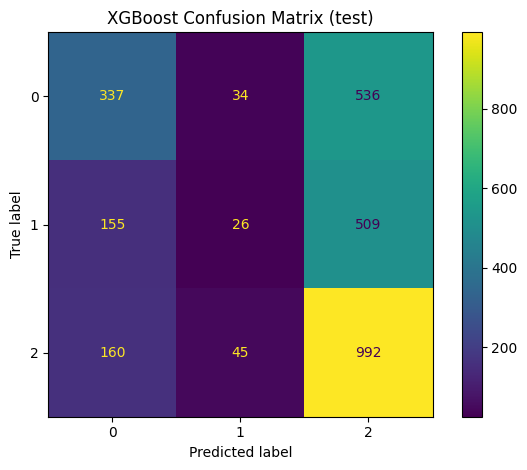

/usr/local/lib/python3.13/dist-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


🏃 View run xgb_baseline_shap_reviewed at: http://100.116.34.36:8080/#/experiments/4/runs/8096cf644988469fa00755b7a275ff72
🧪 View experiment at: http://100.116.34.36:8080/#/experiments/4


In [11]:
# ------------------------------------------------------------
# 0. Làm sạch đầu vào và xác minh dữ liệu
# ------------------------------------------------------------
for _name in ["X_train", "X_valid", "X_test"]:
    _X = globals()[_name].copy()
    _X = _X.replace([np.inf, -np.inf], np.nan)
    _X = _X.apply(pd.to_numeric, errors="coerce")
    globals()[_name] = _X.astype("float32")

X_valid = X_valid.reindex(columns=X_train.columns)
X_test = X_test.reindex(columns=X_train.columns)
features = list(X_train.columns)
assert list(X_valid.columns) == features and list(X_test.columns) == features

print("XGBoost:", xgb.__version__, "| SHAP:", shap.__version__)
print("Feature count:", len(features))
print("Train/valid/test:", X_train.shape, X_valid.shape, X_test.shape)
print("Train labels:", sorted(pd.Series(y_train).unique()))

# Baseline: majority class và Logistic Regression; imputer được fit chỉ trên train.
# Logistic Regression có thể mất thêm thời gian, nhưng tạo mốc so sánh hữu ích.
baseline_rows = []
for baseline_name, baseline_model in [
    ("majority_class", DummyClassifier(strategy="most_frequent")),
    ("logistic_regression", make_pipeline(
        SimpleImputer(strategy="median", add_indicator=True),
        LogisticRegression(max_iter=1500, class_weight="balanced", random_state=42)
    )),
]:
    try:
        baseline_model.fit(X_train, y_train)
        pred_b = baseline_model.predict(X_test)
        row = {
            "model": baseline_name,
            "accuracy": accuracy_score(y_test, pred_b),
            "balanced_accuracy": balanced_accuracy_score(y_test, pred_b),
            "macro_f1": f1_score(y_test, pred_b, average="macro", zero_division=0),
        }
        if hasattr(baseline_model, "predict_proba"):
            prob_b = baseline_model.predict_proba(X_test)
            row["log_loss"] = log_loss(y_test, prob_b, labels=baseline_model.classes_)
        baseline_rows.append(row)
    except Exception as exc:
        print(f"Baseline {baseline_name} không chạy được: {exc}")

baseline_results = pd.DataFrame(baseline_rows)
print("\n===== BASELINE TRÊN TEST (chỉ dùng để đối chiếu; không tune theo test) =====")
display(baseline_results.round(4))
baseline_results.to_csv("mlflow_artifacts/baseline_results.csv", index=False)

params = {
    "objective": "multi:softprob",
    "num_class": 3,
    "learning_rate": 0.05,
    "max_depth": 4,
    "n_estimators": 500,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "eval_metric": "mlogloss",
    "early_stopping_rounds": 30,
    "tree_method": "hist",
    "random_state": 42,
    "n_jobs": -1,
}

with mlflow.start_run(run_name="xgb_baseline_shap_reviewed") as run:
    run_id = run.info.run_id
    mlflow.log_params(params)
    mlflow.log_param("n_features", len(features))
    mlflow.log_param("max_missing_rate", MAX_MISSING_RATE)
    mlflow.log_param("n_train", len(X_train))
    mlflow.log_param("n_valid", len(X_valid))
    mlflow.log_param("n_test", len(X_test))

    model = xgb.XGBClassifier(**params)
    model.fit(X_train, y_train, eval_set=[(X_valid, y_valid)], verbose=50)

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)
    acc = accuracy_score(y_test, y_pred)
    bal_acc = balanced_accuracy_score(y_test, y_pred)
    macro_f1 = f1_score(y_test, y_pred, average="macro", zero_division=0)
    loss = log_loss(y_test, y_prob, labels=model.classes_)
    # Multiclass Brier score: trung bình tổng bình phương sai số one-hot.
    y_onehot = np.eye(len(model.classes_))[pd.Index(model.classes_).get_indexer(y_test)]
    brier = float(np.mean(np.sum((y_prob - y_onehot) ** 2, axis=1)))

    print("\n===== KẾT QUẢ XGBOOST =====")
    print(f"Accuracy          : {acc:.4f}")
    print(f"Balanced accuracy : {bal_acc:.4f}")
    print(f"Macro F1          : {macro_f1:.4f}")
    print(f"Log Loss          : {loss:.4f}")
    print(f"Multiclass Brier  : {brier:.4f}")
    print("Best iteration:", getattr(model, "best_iteration", None))
    mlflow.log_metrics({
        "accuracy": float(acc), "balanced_accuracy": float(bal_acc),
        "macro_f1": float(macro_f1), "log_loss": float(loss),
        "multiclass_brier": brier,
    })
    if hasattr(model, "best_iteration") and model.best_iteration is not None:
        mlflow.log_metric("best_iteration", float(model.best_iteration))

    report_dict = classification_report(
        y_test, y_pred, labels=model.classes_, output_dict=True, zero_division=0
    )
    report = classification_report(
        y_test, y_pred, labels=model.classes_, zero_division=0
    )
    print("\n===== CLASSIFICATION REPORT =====\n", report)
    with open("mlflow_artifacts/classification_report.txt", "w", encoding="utf-8") as f:
        f.write(report)
    with open("mlflow_artifacts/classification_report.json", "w", encoding="utf-8") as f:
        json.dump(report_dict, f, ensure_ascii=False, indent=2)
    mlflow.log_artifact("mlflow_artifacts/classification_report.txt")
    mlflow.log_artifact("mlflow_artifacts/classification_report.json")
    mlflow.log_artifact("mlflow_artifacts/baseline_results.csv")

    cm = confusion_matrix(y_test, y_pred, labels=model.classes_)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model.classes_)
    disp.plot(values_format="d")
    plt.title("XGBoost Confusion Matrix (test)")
    plt.tight_layout()
    plt.savefig("mlflow_artifacts/confusion_matrix.png", dpi=150, bbox_inches="tight")
    mlflow.log_artifact("mlflow_artifacts/confusion_matrix.png")
    plt.show()
    plt.close()

    # Feature importance gain: bổ sung một góc nhìn định lượng, không thay SHAP.
    # XGBoost có thể bỏ qua feature không được dùng trong cây; dựng lại đúng theo tên.
    gain_map = model.get_booster().get_score(importance_type="gain")
    importance = pd.DataFrame({"feature": features})
    importance["gain"] = importance["feature"].map(gain_map).fillna(0.0)
    importance = importance.sort_values("gain", ascending=False)
    importance.to_csv("mlflow_artifacts/feature_importance_gain.csv", index=False)
    mlflow.log_artifact("mlflow_artifacts/feature_importance_gain.csv")

    # Log model bằng tiện ích Colab có sẵn trong notebook gốc.
    colab_utils.log_model(
        model,
        artifact_path="xgboost_model",
        input_example=X_train.head(3),
    )


SHAP shape theo lớp: [(500, 131), (500, 131), (500, 131)]
Đang giải thích class code=2. Hãy đối chiếu bảng mapping y_result_code/y_result.
🏃 View run xgb_baseline_shap_reviewed at: http://100.116.34.36:8080/#/experiments/4/runs/8096cf644988469fa00755b7a275ff72
🧪 View experiment at: http://100.116.34.36:8080/#/experiments/4


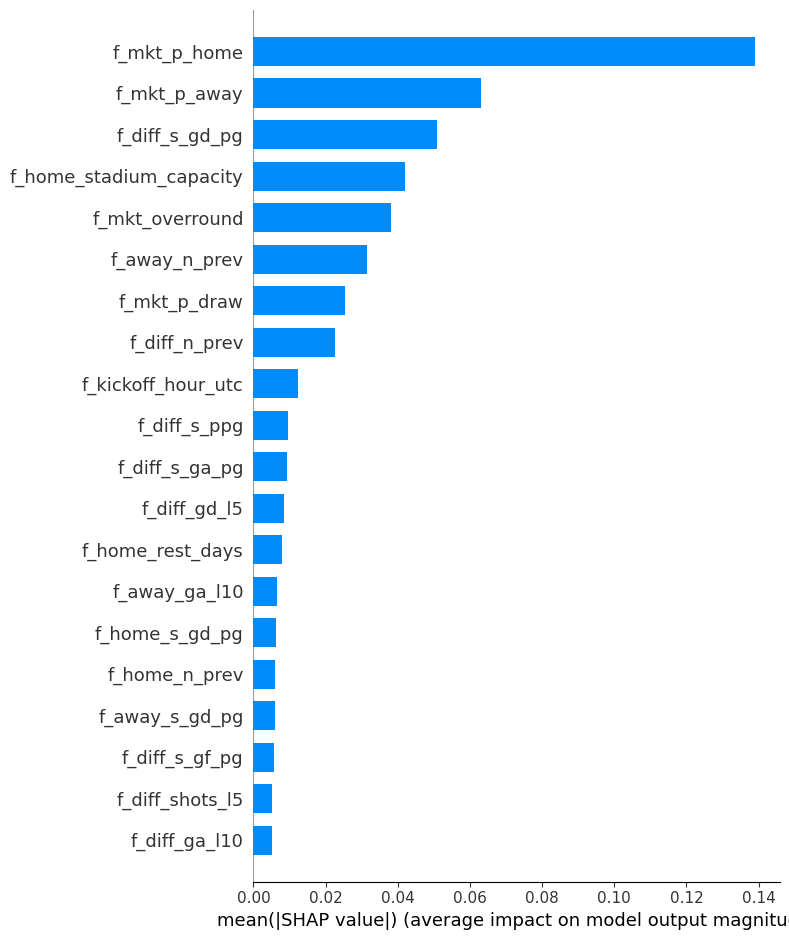

🏃 View run xgb_baseline_shap_reviewed at: http://100.116.34.36:8080/#/experiments/4/runs/8096cf644988469fa00755b7a275ff72
🧪 View experiment at: http://100.116.34.36:8080/#/experiments/4


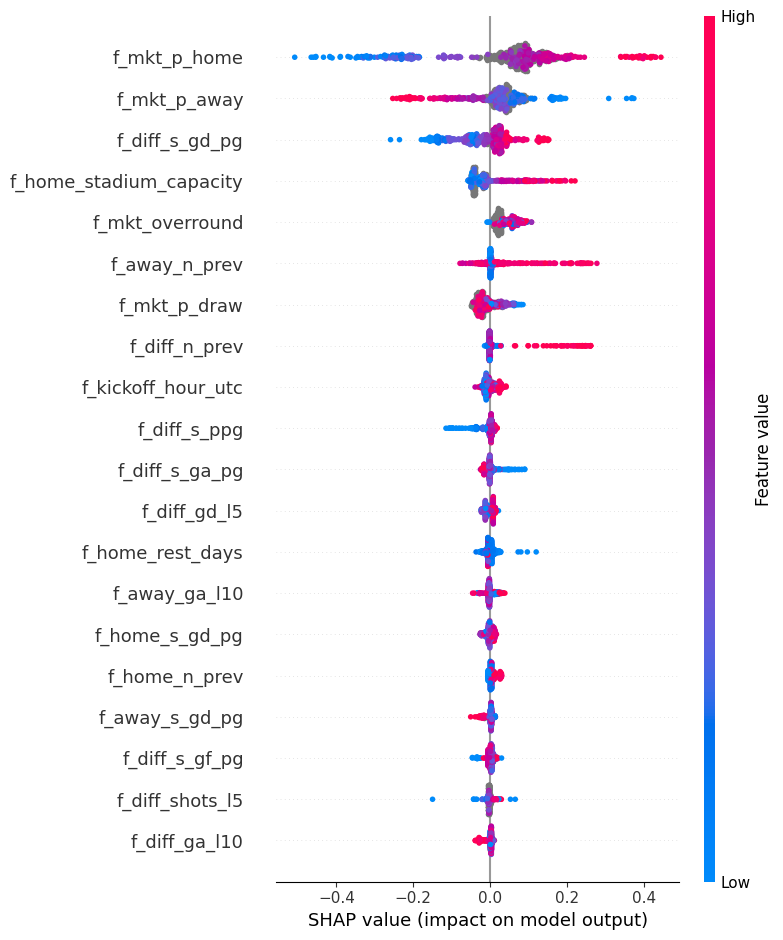

In [12]:
# ------------------------------------------------------------
# SHAP: giải thích đóng góp feature cho từng lớp
# ------------------------------------------------------------
# Chỉ dùng tối đa 500 dòng test để giới hạn RAM/thời gian.
n_shap = min(500, len(X_test))
X_shap = X_test.iloc[:n_shap].copy()
explainer = shap.TreeExplainer(model)
shap_raw = explainer.shap_values(X_shap)

# Tương thích cả SHAP trả list theo lớp và ndarray 3 chiều.
if isinstance(shap_raw, list):
    shap_by_class = [np.asarray(v) for v in shap_raw]
else:
    shap_arr = np.asarray(shap_raw)
    if shap_arr.ndim == 3 and shap_arr.shape[-1] == len(model.classes_):
        shap_by_class = [shap_arr[:, :, i] for i in range(shap_arr.shape[-1])]
    elif shap_arr.ndim == 2 and len(model.classes_) == 1:
        shap_by_class = [shap_arr]
    else:
        raise ValueError(f"Không nhận diện được SHAP shape {shap_arr.shape}; kiểm tra phiên bản SHAP/XGBoost.")

if len(shap_by_class) != len(model.classes_):
    raise ValueError(
        f"Số output SHAP ({len(shap_by_class)}) không khớp số lớp ({len(model.classes_)})."
    )
print("SHAP shape theo lớp:", [v.shape for v in shap_by_class])

# Chọn lớp theo mã, không gán tên thắng/hòa/thua khi chưa xác minh mapping.
class_idx = 2
class_value = model.classes_[class_idx]
sv_class = shap_by_class[class_idx]
print(f"Đang giải thích class code={class_value}. Hãy đối chiếu bảng mapping y_result_code/y_result.")

plt.figure()
shap.summary_plot(sv_class, X_shap, plot_type="bar", show=False)
plt.tight_layout()
summary_bar_path = "mlflow_artifacts/shap_summary_bar_class_" + str(class_value) + ".png"
plt.savefig(summary_bar_path, dpi=150, bbox_inches="tight")
mlflow.start_run(run_id=run_id)
mlflow.log_artifact(summary_bar_path)
mlflow.end_run()
plt.show()
plt.close()

plt.figure()
shap.summary_plot(sv_class, X_shap, show=False)
plt.tight_layout()
beeswarm_path = "mlflow_artifacts/shap_beeswarm_class_" + str(class_value) + ".png"
plt.savefig(beeswarm_path, dpi=150, bbox_inches="tight")
mlflow.start_run(run_id=run_id)
mlflow.log_artifact(beeswarm_path)
mlflow.end_run()
plt.show()
plt.close()


===== PHÂN TÍCH MỘT TRẬN =====
Trận đấu: Ipswich Town vs Blackburn
Nhãn thực tế: 2 | Nhãn dự đoán: 2
Xác suất theo mã lớp: {0: 0.13399681448936462, 1: 0.2457486093044281, 2: 0.620254635810852}
🏃 View run xgb_baseline_shap_reviewed at: http://100.116.34.36:8080/#/experiments/4/runs/8096cf644988469fa00755b7a275ff72
🧪 View experiment at: http://100.116.34.36:8080/#/experiments/4


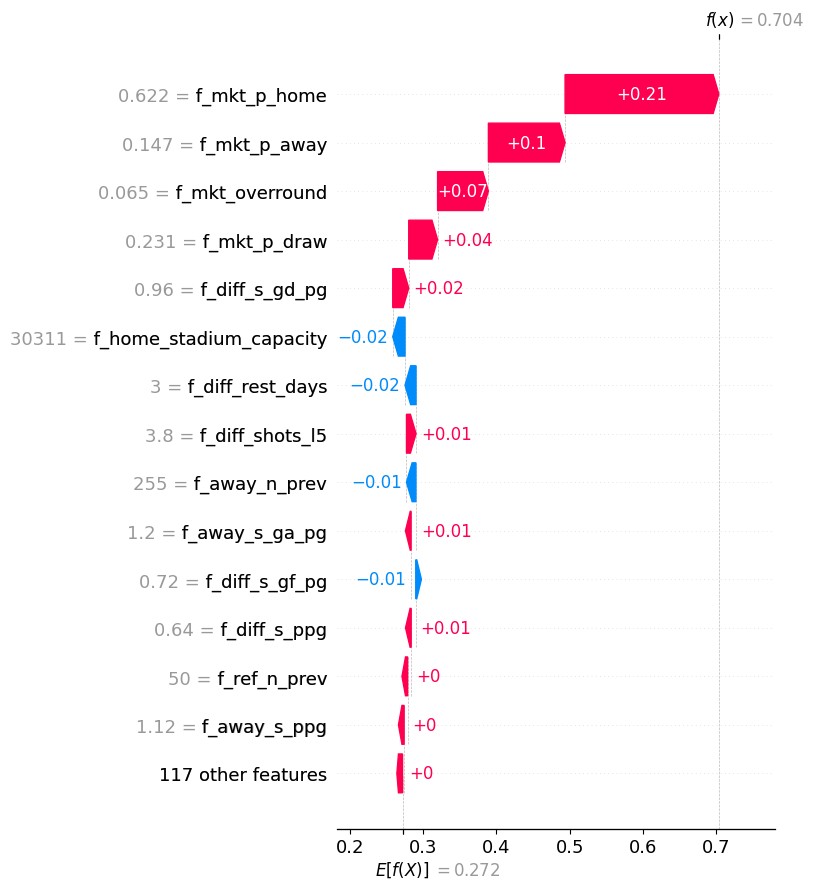

Đã log metrics, baseline, báo cáo, biểu đồ và model vào MLflow.


In [13]:
# ------------------------------------------------------------
# SHAP waterfall: giải thích một dòng test
# ------------------------------------------------------------
row_idx = 0
if row_idx < 0 or row_idx >= len(X_shap) or row_idx >= len(test_df):
    raise IndexError("row_idx nằm ngoài phạm vi X_shap/test_df.")

match_info = test_df.iloc[row_idx]
home = match_info.get("team_home", match_info.get("home_key", "Home"))
away = match_info.get("team_away", match_info.get("away_key", "Away"))
actual = int(y_test.iloc[row_idx])
predicted = int(y_pred[row_idx])
probabilities = y_prob[row_idx]

print("===== PHÂN TÍCH MỘT TRẬN =====")
print(f"Trận đấu: {home} vs {away}")
print(f"Nhãn thực tế: {actual} | Nhãn dự đoán: {predicted}")
print("Xác suất theo mã lớp:", dict(zip(model.classes_.tolist(), probabilities.tolist())))

expected_values = np.asarray(explainer.expected_value)
if expected_values.ndim == 0:
    base_value = float(expected_values)
else:
    if class_idx >= len(expected_values):
        raise ValueError("expected_value không khớp với class_idx.")
    base_value = float(expected_values[class_idx])

explanation = shap.Explanation(
    values=sv_class[row_idx],
    base_values=base_value,
    data=X_shap.iloc[row_idx].to_numpy(),
    feature_names=list(X_shap.columns),
)
shap.plots.waterfall(explanation, max_display=15, show=False)
plt.tight_layout()
waterfall_path = "mlflow_artifacts/shap_waterfall_class_" + str(class_value) + ".png"
plt.savefig(waterfall_path, dpi=150, bbox_inches="tight")
mlflow.start_run(run_id=run_id)
mlflow.log_artifact(waterfall_path)
mlflow.end_run()
plt.show()
plt.close()
print("Đã log metrics, baseline, báo cáo, biểu đồ và model vào MLflow.")


In [14]:
%pip install -q lime

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 9.8 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done


In [16]:
# ============================================================
# SO SÁNH NHIỀU MÔ HÌNH + MLflow + LIME TRONG MỘT RUN DUY NHẤT
# Chạy sau khi notebook đã tạo:
# X_train, X_valid, X_test, y_train, y_valid, y_test
# và đã train XGBoost vào biến `model`.
# ============================================================

import os
import sys
import json
import re
import warnings
import inspect
import subprocess

try:
    from lime.lime_tabular import LimeTabularExplainer
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "lime"])
    from lime.lime_tabular import LimeTabularExplainer

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mlflow
import mlflow.sklearn

from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    HistGradientBoostingClassifier,
)
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    log_loss,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

# ------------------------------------------------------------
# 1. KIỂM TRA DỮ LIỆU
# ------------------------------------------------------------

required_vars = [
    "X_train", "X_valid", "X_test",
    "y_train", "y_valid", "y_test",
]

missing_vars = [v for v in required_vars if v not in globals()]
if missing_vars:
    raise RuntimeError(
        f"Thiếu biến {missing_vars}. "
        "Hãy chạy các cell tiền xử lý dữ liệu trước."
    )

if len(X_train) == 0 or len(X_valid) == 0 or len(X_test) == 0:
    raise ValueError("Train/validation/test không được rỗng.")

FEATURES = list(X_train.columns)


def clean_frame(frame):
    frame = frame.reindex(columns=FEATURES).copy()
    frame = frame.replace([np.inf, -np.inf], np.nan)
    for col in FEATURES:
        frame[col] = pd.to_numeric(frame[col], errors="coerce")
    return frame


Xtr = clean_frame(X_train)
Xva = clean_frame(X_valid)
Xte = clean_frame(X_test)

ytr = np.asarray(y_train).astype(int).ravel()
yva = np.asarray(y_valid).astype(int).ravel()
yte = np.asarray(y_test).astype(int).ravel()

if len(Xtr) != len(ytr) or len(Xva) != len(yva) or len(Xte) != len(yte):
    raise ValueError("Số dòng X và y không khớp.")

CLASSES = np.sort(np.unique(ytr))

if len(CLASSES) < 2:
    raise ValueError(f"Train chỉ có một lớp: {CLASSES}")

if not set(np.unique(yva)).issubset(set(CLASSES)):
    raise ValueError("Validation chứa nhãn không xuất hiện trong train.")

if not set(np.unique(yte)).issubset(set(CLASSES)):
    raise ValueError("Test chứa nhãn không xuất hiện trong train.")

print("Số features:", len(FEATURES))
print("Số dòng train:", len(Xtr))
print("Số dòng validation:", len(Xva))
print("Số dòng test:", len(Xte))
print("Các lớp:", CLASSES.tolist())


# ------------------------------------------------------------
# 2. KHAI BÁO CÁC MÔ HÌNH
# ------------------------------------------------------------

candidate_models = {}

# Dùng lại XGBoost đã train, không train lại mô hình này.
if "model" in globals() and hasattr(model, "predict_proba"):
    candidate_models["XGBoost (đã train)"] = model
else:
    print(
        "CẢNH BÁO: Không tìm thấy biến `model` có predict_proba(). "
        "XGBoost hiện có sẽ không được đưa vào so sánh."
    )

candidate_models.update({
    "Random Forest": make_pipeline(
        SimpleImputer(strategy="median"),
        RandomForestClassifier(
            n_estimators=350,
            min_samples_leaf=3,
            class_weight="balanced_subsample",
            n_jobs=-1,
            random_state=42,
        ),
    ),

    "Extra Trees": make_pipeline(
        SimpleImputer(strategy="median"),
        ExtraTreesClassifier(
            n_estimators=350,
            min_samples_leaf=3,
            class_weight="balanced",
            n_jobs=-1,
            random_state=42,
        ),
    ),

    "HistGradientBoosting": make_pipeline(
        SimpleImputer(strategy="median"),
        HistGradientBoostingClassifier(
            max_iter=180,
            learning_rate=0.06,
            max_leaf_nodes=31,
            l2_regularization=1.0,
            random_state=42,
        ),
    ),

    "MLP Neural Network": make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        MLPClassifier(
            hidden_layer_sizes=(128, 64),
            activation="relu",
            solver="adam",
            alpha=0.001,
            batch_size=256,
            learning_rate_init=0.001,
            max_iter=160,
            early_stopping=True,
            validation_fraction=0.12,
            n_iter_no_change=12,
            random_state=42,
        ),
    ),
})


# ------------------------------------------------------------
# 3. HÀM HỖ TRỢ
# ------------------------------------------------------------

def safe_name(name):
    return re.sub(
        r"[^a-zA-Z0-9_-]+", "_", name.strip().lower()
    ).strip("_")


def get_estimator_classes(estimator):
    if hasattr(estimator, "classes_"):
        return np.asarray(estimator.classes_)

    if hasattr(estimator, "steps"):
        final_estimator = estimator.steps[-1][1]
        if hasattr(final_estimator, "classes_"):
            return np.asarray(final_estimator.classes_)

    return CLASSES


def aligned_proba(estimator, frame):
    """
    Căn chỉnh cột xác suất theo thứ tự CLASSES,
    tránh nhầm thứ tự các lớp giữa các mô hình.
    """
    raw = np.asarray(estimator.predict_proba(frame), dtype=float)
    estimator_classes = get_estimator_classes(estimator)

    aligned = np.zeros((len(frame), len(CLASSES)), dtype=float)

    for j, class_label in enumerate(estimator_classes):
        positions = np.flatnonzero(CLASSES == class_label)
        if len(positions) > 0 and j < raw.shape[1]:
            aligned[:, positions[0]] = raw[:, j]

    row_sums = aligned.sum(axis=1, keepdims=True)

    aligned = np.divide(
        aligned,
        row_sums,
        out=np.full_like(aligned, 1.0 / len(CLASSES)),
        where=row_sums > 0,
    )

    return aligned


def evaluate_model(estimator, frame, y_true, prefix):
    predictions = np.asarray(estimator.predict(frame)).astype(int)
    probabilities = aligned_proba(estimator, frame)

    metrics = {
        f"{prefix}_accuracy": float(
            accuracy_score(y_true, predictions)
        ),
        f"{prefix}_balanced_accuracy": float(
            balanced_accuracy_score(y_true, predictions)
        ),
        f"{prefix}_macro_f1": float(
            f1_score(
                y_true,
                predictions,
                average="macro",
                zero_division=0,
            )
        ),
        f"{prefix}_log_loss": float(
            log_loss(
                y_true,
                probabilities,
                labels=CLASSES,
            )
        ),
    }

    return metrics, predictions, probabilities


def log_estimator_compatibly(estimator, model_slug):
    """
    MLflow 3.x: dùng name không chứa dấu '/'.
    MLflow 2.x: dùng artifact_path để đặt model trong thư mục riêng.
    """
    signature = inspect.signature(mlflow.sklearn.log_model)
    parameters = signature.parameters

    if "name" in parameters:
        mlflow.sklearn.log_model(
            sk_model=estimator,
            name=f"{model_slug}_estimator",
        )
    else:
        mlflow.sklearn.log_model(
            sk_model=estimator,
            artifact_path=f"models/{model_slug}/estimator",
        )


def log_model_artifact(estimator, model_slug):
    try:
        log_estimator_compatibly(estimator, model_slug)
        mlflow.set_tag(f"{model_slug}_model_logging", "success")
        print("Đã log model artifact.")
        return True

    except Exception as exc:
        mlflow.set_tag(
            f"{model_slug}_model_logging",
            f"failed_{type(exc).__name__}",
        )
        print(
            f"Không log được model artifact: "
            f"{type(exc).__name__}: {str(exc)[:300]}"
        )
        return False


# ------------------------------------------------------------
# 4. THƯ MỤC LƯU ARTIFACT
# ------------------------------------------------------------

ARTIFACT_ROOT = "model_comparison_artifacts"
os.makedirs(ARTIFACT_ROOT, exist_ok=True)


# ------------------------------------------------------------
# 5. KHỞI TẠO LIME
# ------------------------------------------------------------

# Dùng median từ train để xử lý NaN cho LIME.
train_medians = Xtr.median(numeric_only=True).reindex(FEATURES)
train_medians = train_medians.fillna(0)

Xtr_lime = Xtr.fillna(train_medians).fillna(0)
Xte_lime = Xte.fillna(train_medians).fillna(0)

# Dùng chung background cho các mô hình để dễ so sánh.
rng = np.random.default_rng(42)
lime_background_size = min(1000, len(Xtr_lime))
background_indices = rng.choice(
    len(Xtr_lime),
    size=lime_background_size,
    replace=False,
)

lime_background = Xtr_lime.iloc[background_indices].to_numpy(dtype=float)

LIME_EXPLANATIONS_PER_MODEL = min(3, len(Xte))
LIME_NUM_FEATURES = min(12, len(FEATURES))
LIME_NUM_SAMPLES = 1500


# ------------------------------------------------------------
# 6. CHUẨN BỊ MỘT RUN MLflow DUY NHẤT
# ------------------------------------------------------------

# Nếu có run đang mở từ cell trước, đóng nó để tránh nested run.
if mlflow.active_run() is not None:
    mlflow.end_run()

results = []
fitted_models = {}
run_id = None
best_model_name = None

with mlflow.start_run(
    run_name="Football_Model_Comparison"
) as active_run:

    run_id = active_run.info.run_id

    mlflow.set_tags({
        "task": "football_match_prediction",
        "experiment_type": "multi_model_comparison",
        "selection_metric": "validation_macro_f1_then_log_loss",
        "explainability": "LIME",
        "all_models_in_one_run": "true",
    })

    mlflow.log_params({
        "feature_count": int(len(FEATURES)),
        "train_rows": int(len(Xtr)),
        "validation_rows": int(len(Xva)),
        "test_rows": int(len(Xte)),
        "class_labels": json.dumps(CLASSES.tolist()),
        "lime_explanations_per_model": int(LIME_EXPLANATIONS_PER_MODEL),
        "lime_num_samples": int(LIME_NUM_SAMPLES),
    })

    # --------------------------------------------------------
    # 7. TRAIN / EVALUATE / LOG TỪNG MÔ HÌNH
    # --------------------------------------------------------

    for model_name, estimator in candidate_models.items():

        slug = safe_name(model_name)
        print("\n" + "=" * 60)
        print(f"MÔ HÌNH: {model_name}")
        print("=" * 60)

        model_dir = os.path.join(ARTIFACT_ROOT, slug)
        lime_dir = os.path.join(model_dir, "lime")
        os.makedirs(lime_dir, exist_ok=True)

        try:
            # XGBoost được tái sử dụng; các mô hình khác được train mới.
            if model_name != "XGBoost (đã train)":
                with warnings.catch_warnings(record=True) as caught:
                    warnings.simplefilter("always")
                    estimator.fit(Xtr, ytr)

                for warning_item in caught[:3]:
                    print(
                        "Cảnh báo train:",
                        str(warning_item.message)[:250],
                    )

            fitted_models[model_name] = estimator

            # Đánh giá validation và test.
            valid_metrics, valid_pred, valid_prob = evaluate_model(
                estimator, Xva, yva, "valid"
            )

            test_metrics, test_pred, test_prob = evaluate_model(
                estimator, Xte, yte, "test"
            )

            model_result = {
                "model": model_name,
                **valid_metrics,
                **test_metrics,
            }
            results.append(model_result)

            # Log metrics trong cùng một run.
            # Prefix model_slug đảm bảo mỗi mô hình có metric riêng.
            for metric_name, metric_value in {
                **valid_metrics,
                **test_metrics,
            }.items():
                mlflow.log_metric(
                    f"{slug}_{metric_name}",
                    float(metric_value),
                )

            mlflow.set_tag(f"{slug}_status", "success")

            print(
                "Validation:",
                {k: round(v, 4) for k, v in valid_metrics.items()},
            )
            print(
                "Test:",
                {k: round(v, 4) for k, v in test_metrics.items()},
            )

            # ------------------------------------------------
            # 8. LOG PARAMS
            # ------------------------------------------------

            if hasattr(estimator, "get_params"):
                try:
                    params = estimator.get_params(deep=True)
                    for param_name, param_value in params.items():
                        if isinstance(
                            param_value,
                            (str, int, float, bool, type(None)),
                        ):
                            key = f"{slug}_{param_name}"
                            value = str(param_value)

                            # Tránh giới hạn độ dài giá trị param.
                            mlflow.log_param(key[:250], value[:500])
                except Exception as param_error:
                    print(
                        "Không log được một số params:",
                        str(param_error)[:200],
                    )

            # ------------------------------------------------
            # 9. CLASSIFICATION REPORT
            # ------------------------------------------------

            report = classification_report(
                yte,
                test_pred,
                labels=CLASSES,
                output_dict=True,
                zero_division=0,
            )

            report_path = os.path.join(
                model_dir,
                "classification_report_test.json",
            )

            with open(report_path, "w", encoding="utf-8") as file:
                json.dump(
                    report,
                    file,
                    ensure_ascii=False,
                    indent=2,
                )

            mlflow.log_artifact(
                report_path,
                artifact_path=f"reports/{slug}",
            )

            # ------------------------------------------------
            # 10. CONFUSION MATRIX
            # ------------------------------------------------

            fig, ax = plt.subplots(figsize=(6, 5))

            ConfusionMatrixDisplay(
                confusion_matrix(
                    yte,
                    test_pred,
                    labels=CLASSES,
                ),
                display_labels=[str(c) for c in CLASSES],
            ).plot(
                ax=ax,
                values_format="d",
                colorbar=False,
            )

            ax.set_title(f"Confusion Matrix — {model_name}")
            fig.tight_layout()

            cm_path = os.path.join(
                model_dir,
                "confusion_matrix_test.png",
            )

            fig.savefig(
                cm_path,
                dpi=150,
                bbox_inches="tight",
            )
            plt.close(fig)

            mlflow.log_artifact(
                cm_path,
                artifact_path=f"confusion_matrices/{slug}",
            )

            # ------------------------------------------------
            # 11. LOG MODEL ARTIFACT — FIX LỖI MLflow 3.x
            # ------------------------------------------------

            log_estimator_compatibly(estimator, slug)

            # ------------------------------------------------
            # 12. LIME CHO TỪNG MÔ HÌNH
            # ------------------------------------------------

            explainer = LimeTabularExplainer(
                training_data=lime_background,
                feature_names=[str(c) for c in FEATURES],
                class_names=[str(c) for c in CLASSES],
                mode="classification",
                discretize_continuous=True,
                random_state=42,
            )

            lime_rows = []

            def lime_predict_fn(arr, _estimator=estimator):
                arr_df = pd.DataFrame(
                    arr,
                    columns=FEATURES,
                )
                return aligned_proba(_estimator, arr_df)

            for row_position in range(LIME_EXPLANATIONS_PER_MODEL):

                original_row = Xte.iloc[[row_position]]
                filled_row = Xte_lime.iloc[[row_position]]
                instance = filled_row.iloc[0].to_numpy(dtype=float)

                explanation = explainer.explain_instance(
                    data_row=instance,
                    predict_fn=lime_predict_fn,
                    labels=list(range(len(CLASSES))),
                    num_features=LIME_NUM_FEATURES,
                    num_samples=LIME_NUM_SAMPLES,
                )

                html_path = os.path.join(
                    lime_dir,
                    f"lime_test_row_{row_position}.html",
                )

                explanation.save_to_file(html_path)

                predicted_class = int(
                    estimator.predict(original_row)[0]
                )

                class_positions = np.flatnonzero(
                    CLASSES == predicted_class
                )

                if len(class_positions) > 0:
                    predicted_class_position = int(class_positions[0])

                    feature_weights = explanation.as_list(
                        label=predicted_class_position
                    )

                    for feature_rule, weight in feature_weights:
                        lime_rows.append({
                            "test_row_position": int(row_position),
                            "test_row_index": str(Xte.index[row_position]),
                            "predicted_class": predicted_class,
                            "feature_rule": feature_rule,
                            "lime_weight": float(weight),
                        })

            lime_csv_path = os.path.join(
                lime_dir,
                "lime_feature_weights.csv",
            )

            pd.DataFrame(lime_rows).to_csv(
                lime_csv_path,
                index=False,
            )

            # Lưu tất cả file LIME vào thư mục riêng của mô hình.
            for filename in os.listdir(lime_dir):
                full_path = os.path.join(lime_dir, filename)
                if os.path.isfile(full_path):
                    mlflow.log_artifact(
                        full_path,
                        artifact_path=f"lime/{slug}",
                    )

            mlflow.log_metric(
                f"{slug}_lime_explanations_created",
                float(LIME_EXPLANATIONS_PER_MODEL),
            )

            print(
                f"Đã lưu model/report/confusion matrix/LIME cho {model_name}"
            )

        except Exception as exc:
            mlflow.set_tag(
                f"{slug}_status",
                f"failed_{type(exc).__name__}",
            )

            print(
                f"LỖI mô hình {model_name}: "
                f"{type(exc).__name__}: {exc}"
            )

    # --------------------------------------------------------
    # 13. BẢNG SO SÁNH CHUNG
    # --------------------------------------------------------

    if not results:
        raise RuntimeError(
            "Không có mô hình nào chạy thành công. "
            "Kiểm tra các thông báo lỗi phía trên."
        )

    comparison_results = pd.DataFrame(results)

    comparison_results = comparison_results.sort_values(
        by=["valid_macro_f1", "valid_log_loss"],
        ascending=[False, True],
    ).reset_index(drop=True)

    best_model_name = str(comparison_results.iloc[0]["model"])

    # Log mô hình tốt nhất theo validation.
    mlflow.set_tag(
        "best_model_by_validation",
        best_model_name,
    )

    mlflow.log_metric(
        "comparison_successful_models",
        float(len(comparison_results)),
    )

    # CSV tổng hợp tất cả mô hình.
    summary_csv_path = os.path.join(
        ARTIFACT_ROOT,
        "model_comparison_results.csv",
    )

    comparison_results.to_csv(
        summary_csv_path,
        index=False,
    )

    mlflow.log_artifact(
        summary_csv_path,
        artifact_path="summary",
    )

    # JSON ghi nhận mô hình tốt nhất theo validation.
    best_model_info_path = os.path.join(
        ARTIFACT_ROOT,
        "best_model_by_validation.json",
    )

    with open(best_model_info_path, "w", encoding="utf-8") as file:
        json.dump(
            {
                "best_model": best_model_name,
                "selection_metric": "valid_macro_f1",
                "tie_breaker": "valid_log_loss",
                "run_id": run_id,
            },
            file,
            ensure_ascii=False,
            indent=2,
        )

    mlflow.log_artifact(
        best_model_info_path,
        artifact_path="summary",
    )


# ------------------------------------------------------------
# 14. HIỂN THỊ KẾT QUẢ
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("KẾT QUẢ SO SÁNH MÔ HÌNH")
print("=" * 70)

display(comparison_results.round(4))

print("\nMô hình tốt nhất theo validation:", best_model_name)
print("MLflow Run ID:", run_id)
print("Tất cả mô hình nằm trong cùng run: Football_Model_Comparison")
print("Mở MLflow UI → Experiment → Run → Metrics / Artifacts.")

Số features: 131
Số dòng train: 12806
Số dòng validation: 2712
Số dòng test: 2794
Các lớp: [0, 1, 2]

MÔ HÌNH: XGBoost (đã train)
Validation: {'valid_accuracy': 0.4952, 'valid_balanced_accuracy': 0.4224, 'valid_macro_f1': 0.378, 'valid_log_loss': 1.0153}
Test: {'test_accuracy': 0.485, 'test_balanced_accuracy': 0.4127, 'test_macro_f1': 0.3704, 'test_log_loss': 1.0211}
LỖI mô hình XGBoost (đã train): MlflowException: The saved sklearn model references untrusted types. If you are sure loading these types is safe, set the 'skops_trusted_types' parameter when calling 'log_model' or 'save_model' to the list of trusted types. Root error: Untrusted types found in the file: ['xgboost.core.Booster', 'xgboost.sklearn.XGBClassifier'].

MÔ HÌNH: Random Forest
Cảnh báo train: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
Validation: {'valid_accuracy': 0.4956, 'vali

,model,valid_accuracy,valid_balanced_accuracy,valid_macro_f1,valid_log_loss,test_accuracy,test_balanced_accuracy,test_macro_f1,test_log_loss
0,Extra Trees,0.4937,0.4345,0.3996,1.0197,0.4903,0.4307,0.3923,1.0209
1,Random Forest,0.4956,0.4314,0.3923,1.0171,0.4911,0.4264,0.3844,1.0190
2,MLP Neural Network,0.4849,0.4197,0.3809,1.1254,0.4728,0.4139,0.3823,1.2667
3,XGBoost (đã train),0.4952,0.4224,0.3780,1.0153,0.4850,0.4127,0.3704,1.0211
4,HistGradientBoosting,0.4893,0.4124,0.3615,1.0196,0.4832,0.4043,0.3501,1.0288



Mô hình tốt nhất theo validation: Extra Trees
MLflow Run ID: b13febd5540b45ddb0605311a8a8a0de
Tất cả mô hình nằm trong cùng run: Football_Model_Comparison
Mở MLflow UI → Experiment → Run → Metrics / Artifacts.


Test row: 68
Giá trị feature dùng để giải thích:


,f_home_n_prev,f_away_n_prev,f_diff_n_prev,f_home_pts_l3,f_away_pts_l3,f_diff_pts_l3,f_home_gf_l3,f_away_gf_l3,f_diff_gf_l3,f_home_ga_l3,...,f_mkt_overround,f_dow,f_month,f_is_weekend,f_kickoff_hour_utc,f_comp_tier,f_home_stadium_capacity,f_ref_n_prev,f_home_form5_points_rate,f_away_form5_points_rate
68,109.0,255.0,-146.0,2.333333,0.666667,1.666667,1.333333,0.666667,0.666667,0.333333,...,0.065297,6.0,1.0,1.0,12.0,2.0,30311.0,50.0,0.666667,0.4



LIME — XGBoost (đã train)
Dự đoán lớp: 2
Xác suất theo lớp: {'0': 0.134, '1': 0.2457, '2': 0.6203}


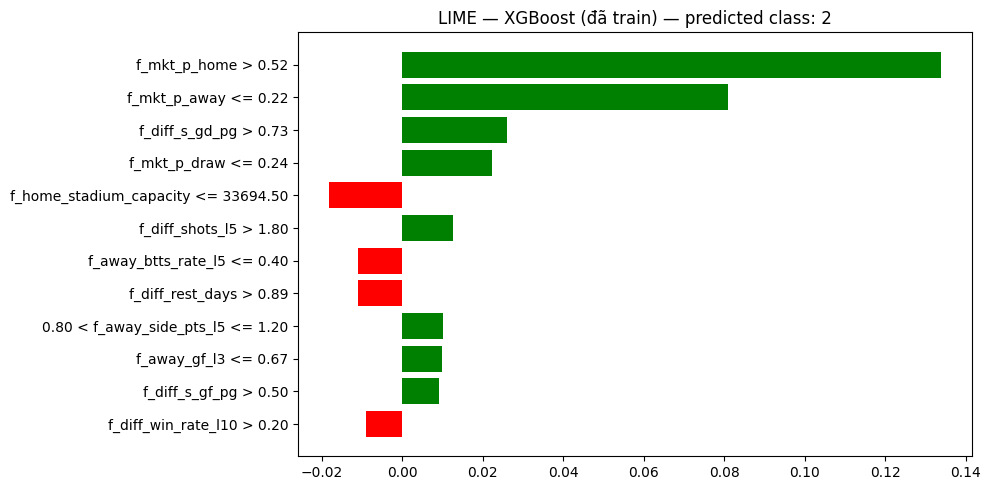

,Model,Predicted Class,Feature / Condition,LIME Weight
0,XGBoost (đã train),2,f_mkt_p_home > 0.52,0.13391
1,XGBoost (đã train),2,f_mkt_p_away <= 0.22,0.08098
2,XGBoost (đã train),2,f_diff_s_gd_pg > 0.73,0.02615
3,XGBoost (đã train),2,f_mkt_p_draw <= 0.24,0.02241
4,XGBoost (đã train),2,f_home_stadium_capacity <= 33694.50,-0.01828
5,XGBoost (đã train),2,f_diff_shots_l5 > 1.80,0.01273
6,XGBoost (đã train),2,f_away_btts_rate_l5 <= 0.40,-0.01104
7,XGBoost (đã train),2,f_diff_rest_days > 0.89,-0.01097
8,XGBoost (đã train),2,0.80 < f_away_side_pts_l5 <= 1.20,0.01024
9,XGBoost (đã train),2,f_away_gf_l3 <= 0.67,0.00977


Đã lưu LIME HTML/CSV cho XGBoost (đã train)

LIME — Random Forest
Dự đoán lớp: 2
Xác suất theo lớp: {'0': 0.1543, '1': 0.2902, '2': 0.5555}


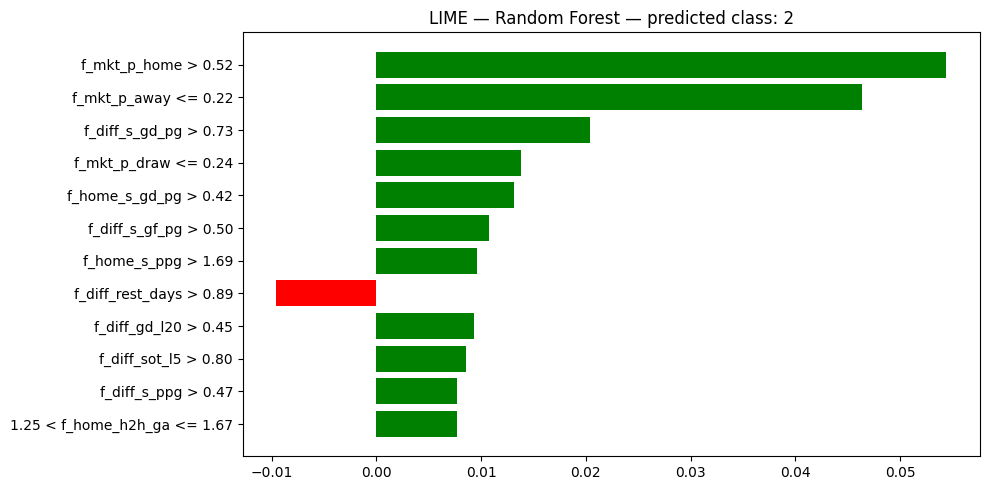

,Model,Predicted Class,Feature / Condition,LIME Weight
0,Random Forest,2,f_mkt_p_home > 0.52,0.05442
1,Random Forest,2,f_mkt_p_away <= 0.22,0.04634
2,Random Forest,2,f_diff_s_gd_pg > 0.73,0.02038
3,Random Forest,2,f_mkt_p_draw <= 0.24,0.01382
4,Random Forest,2,f_home_s_gd_pg > 0.42,0.01317
5,Random Forest,2,f_diff_s_gf_pg > 0.50,0.01073
6,Random Forest,2,f_home_s_ppg > 1.69,0.00961
7,Random Forest,2,f_diff_rest_days > 0.89,-0.00956
8,Random Forest,2,f_diff_gd_l20 > 0.45,0.00932
9,Random Forest,2,f_diff_sot_l5 > 0.80,0.00858


Đã lưu LIME HTML/CSV cho Random Forest

LIME — Extra Trees
Dự đoán lớp: 2
Xác suất theo lớp: {'0': 0.1617, '1': 0.3098, '2': 0.5285}


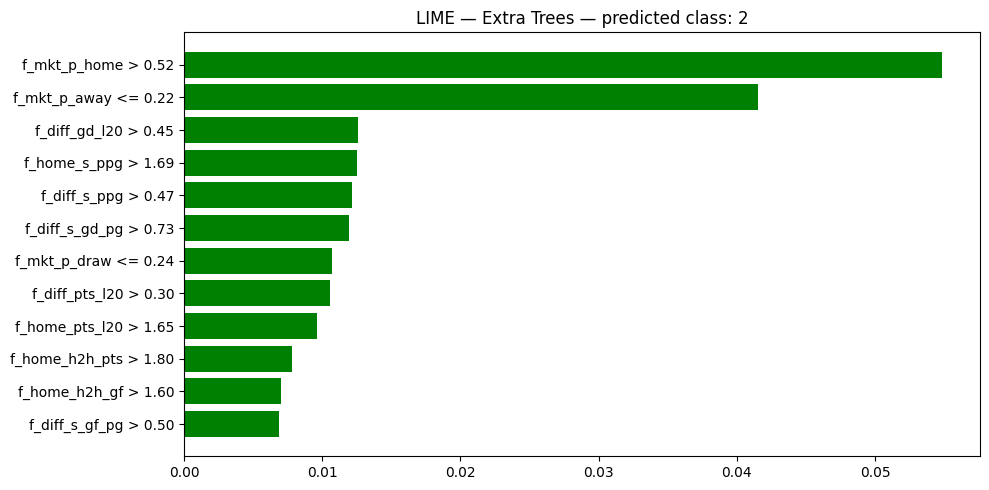

,Model,Predicted Class,Feature / Condition,LIME Weight
0,Extra Trees,2,f_mkt_p_home > 0.52,0.05485
1,Extra Trees,2,f_mkt_p_away <= 0.22,0.04156
2,Extra Trees,2,f_diff_gd_l20 > 0.45,0.01256
3,Extra Trees,2,f_home_s_ppg > 1.69,0.01249
4,Extra Trees,2,f_diff_s_ppg > 0.47,0.01218
5,Extra Trees,2,f_diff_s_gd_pg > 0.73,0.01195
6,Extra Trees,2,f_mkt_p_draw <= 0.24,0.01069
7,Extra Trees,2,f_diff_pts_l20 > 0.30,0.01054
8,Extra Trees,2,f_home_pts_l20 > 1.65,0.00962
9,Extra Trees,2,f_home_h2h_pts > 1.80,0.00783


Đã lưu LIME HTML/CSV cho Extra Trees

LIME — HistGradientBoosting
Dự đoán lớp: 2
Xác suất theo lớp: {'0': 0.1488, '1': 0.3367, '2': 0.5145}


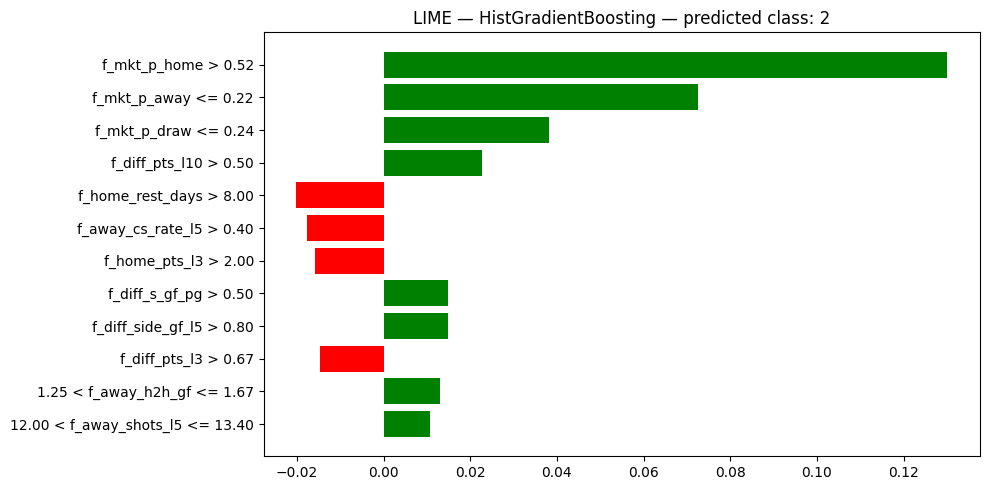

,Model,Predicted Class,Feature / Condition,LIME Weight
0,HistGradientBoosting,2,f_mkt_p_home > 0.52,0.13009
1,HistGradientBoosting,2,f_mkt_p_away <= 0.22,0.07260
2,HistGradientBoosting,2,f_mkt_p_draw <= 0.24,0.03814
3,HistGradientBoosting,2,f_diff_pts_l10 > 0.50,0.02262
4,HistGradientBoosting,2,f_home_rest_days > 8.00,-0.02015
5,HistGradientBoosting,2,f_away_cs_rate_l5 > 0.40,-0.01771
6,HistGradientBoosting,2,f_home_pts_l3 > 2.00,-0.01582
7,HistGradientBoosting,2,f_diff_s_gf_pg > 0.50,0.01498
8,HistGradientBoosting,2,f_diff_side_gf_l5 > 0.80,0.01491
9,HistGradientBoosting,2,f_diff_pts_l3 > 0.67,-0.01463


Đã lưu LIME HTML/CSV cho HistGradientBoosting

LIME — MLP Neural Network
Dự đoán lớp: 2
Xác suất theo lớp: {'0': 0.1756, '1': 0.2054, '2': 0.619}


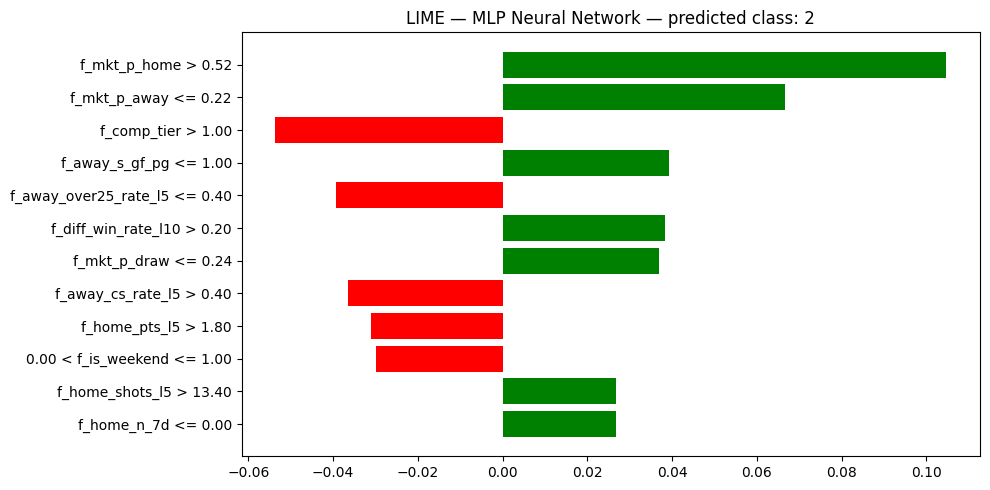

,Model,Predicted Class,Feature / Condition,LIME Weight
0,MLP Neural Network,2,f_mkt_p_home > 0.52,0.10476
1,MLP Neural Network,2,f_mkt_p_away <= 0.22,0.06678
2,MLP Neural Network,2,f_comp_tier > 1.00,-0.05364
3,MLP Neural Network,2,f_away_s_gf_pg <= 1.00,0.03933
4,MLP Neural Network,2,f_away_over25_rate_l5 <= 0.40,-0.03931
5,MLP Neural Network,2,f_diff_win_rate_l10 > 0.20,0.03840
6,MLP Neural Network,2,f_mkt_p_draw <= 0.24,0.03697
7,MLP Neural Network,2,f_away_cs_rate_l5 > 0.40,-0.03657
8,MLP Neural Network,2,f_home_pts_l5 > 1.80,-0.03115
9,MLP Neural Network,2,0.00 < f_is_weekend <= 1.00,-0.02993


Đã lưu LIME HTML/CSV cho MLP Neural Network

BẢNG TỔNG HỢP LIME CỦA TẤT CẢ MÔ HÌNH


,Feature / Condition,LIME Weight,Model,Predicted Class
0,f_mkt_p_home > 0.52,0.054847,Extra Trees,2
1,f_mkt_p_away <= 0.22,0.041563,Extra Trees,2
2,f_diff_gd_l20 > 0.45,0.012564,Extra Trees,2
3,f_home_s_ppg > 1.69,0.012493,Extra Trees,2
4,f_diff_s_ppg > 0.47,0.012179,Extra Trees,2
5,f_diff_s_gd_pg > 0.73,0.011951,Extra Trees,2
6,f_mkt_p_draw <= 0.24,0.010690,Extra Trees,2
7,f_diff_pts_l20 > 0.30,0.010541,Extra Trees,2
8,f_home_pts_l20 > 1.65,0.009617,Extra Trees,2
9,f_home_h2h_pts > 1.80,0.007826,Extra Trees,2



MLflow Run ID: 2796a62fdafe48b79e2726e2abf2c267
Xem các file LIME tại MLflow → Artifacts → lime_display/
🏃 View run Football_Model_Comparison_LIME at: http://100.116.34.36:8080/#/experiments/4/runs/2796a62fdafe48b79e2726e2abf2c267
🧪 View experiment at: http://100.116.34.36:8080/#/experiments/4


In [17]:
# ============================================================
# HIỂN THỊ KẾT QUẢ LIME CHO TỪNG MÔ HÌNH
# Chạy sau cell so sánh mô hình
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML
from lime.lime_tabular import LimeTabularExplainer
import mlflow

# Kiểm tra các biến đã được tạo ở cell so sánh
assert "fitted_models" in globals(), "Không tìm thấy fitted_models."
assert "Xte" in globals() and "Xte_lime" in globals()
assert "Xtr_lime" in globals() and "FEATURES" in globals()
assert "CLASSES" in globals()

# Chọn dòng test cần giải thích
TEST_ROW_POSITION = 0
NUM_FEATURES = min(12, len(FEATURES))
NUM_SAMPLES = 1500

# Dùng chung background cho tất cả mô hình
rng = np.random.default_rng(42)
n_background = min(1000, len(Xtr_lime))
background_idx = rng.choice(
    len(Xtr_lime), size=n_background, replace=False
)
background = Xtr_lime.iloc[background_idx].to_numpy(dtype=float)

explainer = LimeTabularExplainer(
    training_data=background,
    feature_names=[str(c) for c in FEATURES],
    class_names=[str(c) for c in CLASSES],
    mode="classification",
    discretize_continuous=True,
    random_state=42,
)

# Giữ nguyên run hiện tại nếu vẫn còn active.
# Nếu run đã đóng, mở một run mới để log kết quả LIME bổ sung.
active_run = mlflow.active_run()
started_new_run = active_run is None

if started_new_run:
    active_run = mlflow.start_run(
        run_name="Football_Model_Comparison_LIME"
    )

lime_run_id = active_run.info.run_id

try:
    row_df = Xte.iloc[[TEST_ROW_POSITION]]
    row_filled = Xte_lime.iloc[TEST_ROW_POSITION].to_numpy(dtype=float)

    print("Test row:", Xte.index[TEST_ROW_POSITION])
    print("Giá trị feature dùng để giải thích:")
    display(row_df)

    all_lime_weights = []

    for model_name, estimator in fitted_models.items():
        slug = safe_name(model_name)

        print("\n" + "=" * 70)
        print(f"LIME — {model_name}")
        print("=" * 70)

        try:
            # Lấy dự đoán và xác suất của mô hình
            pred_class = int(estimator.predict(row_df)[0])
            pred_prob = aligned_proba(estimator, row_df)[0]

            print(f"Dự đoán lớp: {pred_class}")
            print(
                "Xác suất theo lớp:",
                {
                    str(CLASSES[i]): round(float(pred_prob[i]), 4)
                    for i in range(len(CLASSES))
                },
            )

            # LIME cần predict_fn trả về xác suất theo cùng thứ tự lớp
            def predict_fn(arr, _model=estimator):
                arr_df = pd.DataFrame(arr, columns=FEATURES)
                return aligned_proba(_model, arr_df)

            exp = explainer.explain_instance(
                data_row=row_filled,
                predict_fn=predict_fn,
                labels=list(range(len(CLASSES))),
                num_features=NUM_FEATURES,
                num_samples=NUM_SAMPLES,
            )

            # Chọn giải thích cho lớp mà mô hình dự đoán
            class_position = int(np.where(CLASSES == pred_class)[0][0])
            weights = exp.as_list(label=class_position)

            # Hiển thị biểu đồ ngay trong Colab
            fig = exp.as_pyplot_figure(label=class_position)
            fig.set_size_inches(10, 5)
            plt.title(
                f"LIME — {model_name} — predicted class: {pred_class}"
            )
            plt.tight_layout()
            plt.show()

            # Hiển thị bảng trọng số LIME
            weights_df = pd.DataFrame(
                weights,
                columns=["Feature / Condition", "LIME Weight"],
            )
            weights_df["Model"] = model_name
            weights_df["Predicted Class"] = pred_class

            display(
                weights_df[
                    ["Model", "Predicted Class",
                     "Feature / Condition", "LIME Weight"]
                ].style.format({"LIME Weight": "{:.5f}"})
            )

            all_lime_weights.append(weights_df)

            # Lưu HTML giải thích tương tác
            out_dir = os.path.join(
                "model_comparison_artifacts", slug, "lime_display"
            )
            os.makedirs(out_dir, exist_ok=True)

            html_path = os.path.join(
                out_dir, f"lime_test_row_{TEST_ROW_POSITION}.html"
            )
            exp.save_to_file(html_path)

            csv_path = os.path.join(
                out_dir, f"lime_test_row_{TEST_ROW_POSITION}.csv"
            )
            weights_df.to_csv(csv_path, index=False)

            # Log vào run MLflow
            mlflow.log_artifact(
                html_path,
                artifact_path=f"lime_display/{slug}",
            )
            mlflow.log_artifact(
                csv_path,
                artifact_path=f"lime_display/{slug}",
            )

            print(f"Đã lưu LIME HTML/CSV cho {model_name}")

        except Exception as e:
            print(
                f"Lỗi khi tạo LIME cho {model_name}: "
                f"{type(e).__name__}: {e}"
            )

    # Bảng so sánh LIME giữa các mô hình
    if all_lime_weights:
        combined_lime = pd.concat(all_lime_weights, ignore_index=True)

        print("\nBẢNG TỔNG HỢP LIME CỦA TẤT CẢ MÔ HÌNH")
        display(
            combined_lime.sort_values(
                ["Model", "LIME Weight"],
                ascending=[True, False],
            ).reset_index(drop=True)
        )

        combined_csv = os.path.join(
            "model_comparison_artifacts",
            f"lime_comparison_test_row_{TEST_ROW_POSITION}.csv",
        )
        combined_lime.to_csv(combined_csv, index=False)

        mlflow.log_artifact(
            combined_csv,
            artifact_path="lime_display/summary",
        )

    print("\nMLflow Run ID:", lime_run_id)
    print("Xem các file LIME tại MLflow → Artifacts → lime_display/")

finally:
    # Chỉ đóng run nếu cell này tự tạo run mới
    if started_new_run and mlflow.active_run() is not None:
        mlflow.end_run()

SHAP version: 0.52.0
Test row: 68
Số mô hình: 5

SHAP: XGBoost (đã train)


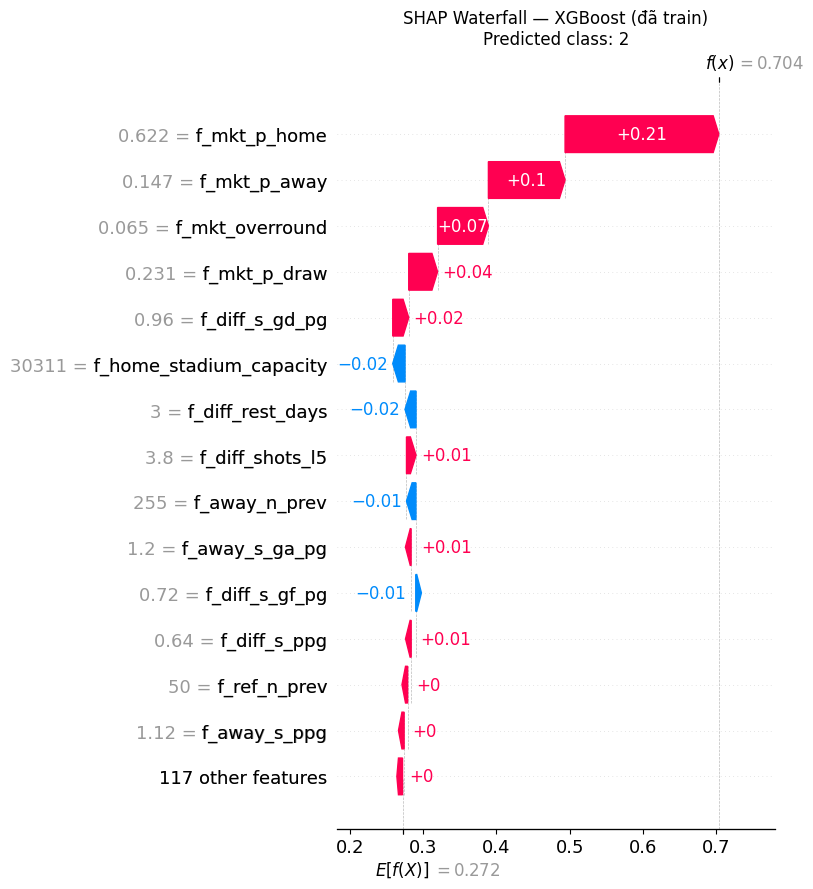

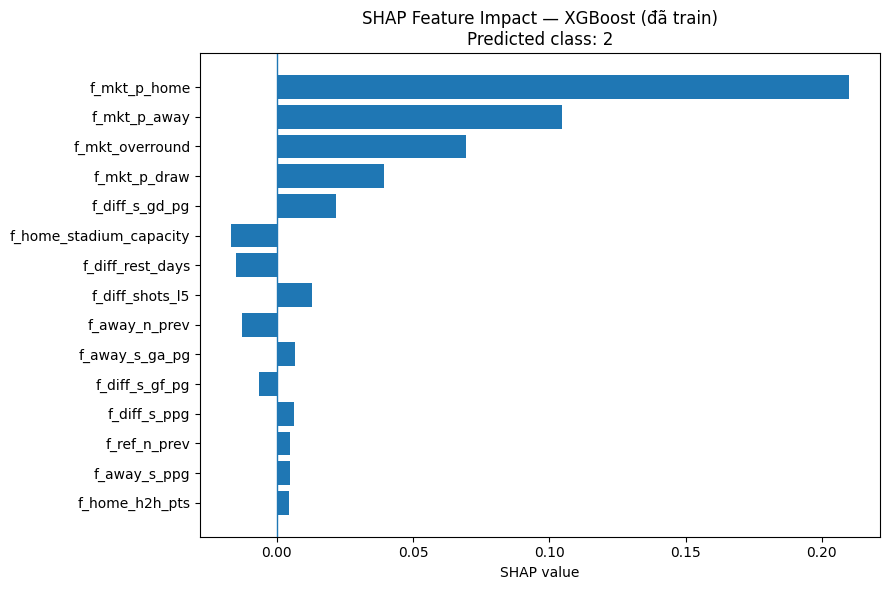

Phương pháp: TreeExplainer
Lớp được giải thích: 2
Top features theo |SHAP|:


,feature,feature_value,shap_value,abs_shap_value
118,f_mkt_p_home,0.62166,0.21001,0.21001
120,f_mkt_p_away,0.14713,0.10471,0.10471
121,f_mkt_overround,0.06530,0.06938,0.06938
119,f_mkt_p_draw,0.23121,0.03942,0.03942
95,f_diff_s_gd_pg,0.96000,0.02184,0.02184
127,f_home_stadium_capacity,30311.00000,-0.01678,0.01678
108,f_diff_rest_days,3.00000,-0.01504,0.01504
38,f_diff_shots_l5,3.80000,0.01304,0.01304
1,f_away_n_prev,255.00000,-0.01290,0.01290
91,f_away_s_ga_pg,1.20000,0.00661,0.00661



SHAP: Random Forest


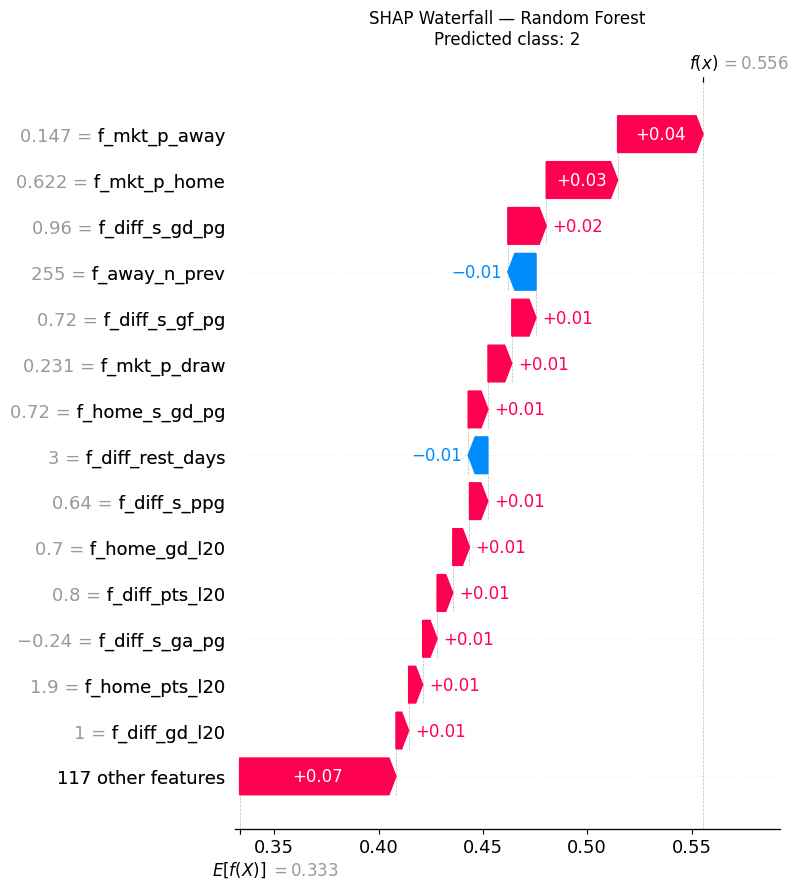

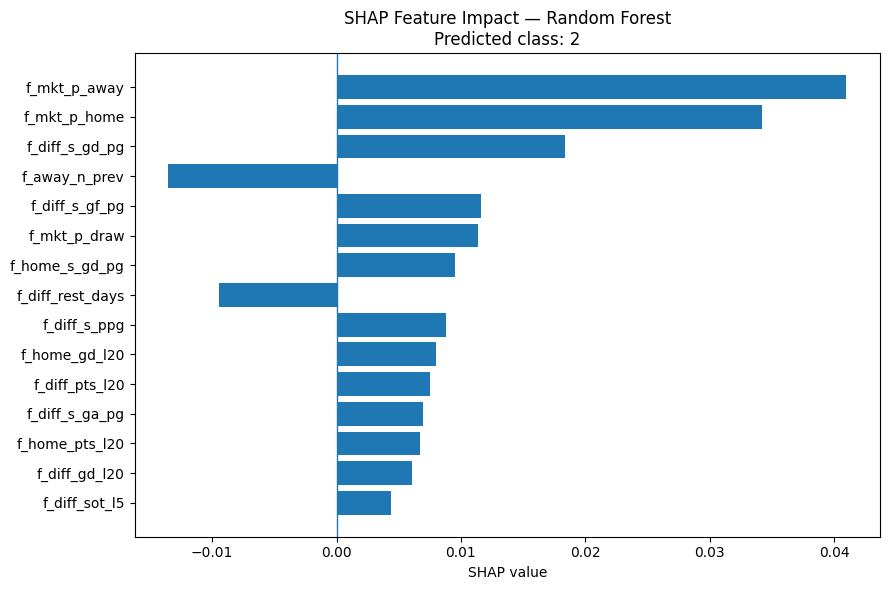

Phương pháp: TreeExplainer
Lớp được giải thích: 2
Top features theo |SHAP|:


,feature,feature_value,shap_value,abs_shap_value
120,f_mkt_p_away,0.14713,0.04098,0.04098
118,f_mkt_p_home,0.62166,0.03423,0.03423
95,f_diff_s_gd_pg,0.96000,0.01840,0.01840
1,f_away_n_prev,255.00000,-0.01351,0.01351
89,f_diff_s_gf_pg,0.72000,0.01163,0.01163
119,f_mkt_p_draw,0.23121,0.01141,0.01141
93,f_home_s_gd_pg,0.72000,0.00949,0.00949
108,f_diff_rest_days,3.00000,-0.00942,0.00942
86,f_diff_s_ppg,0.64000,0.00878,0.00878
69,f_home_gd_l20,0.70000,0.00801,0.00801



SHAP: Extra Trees


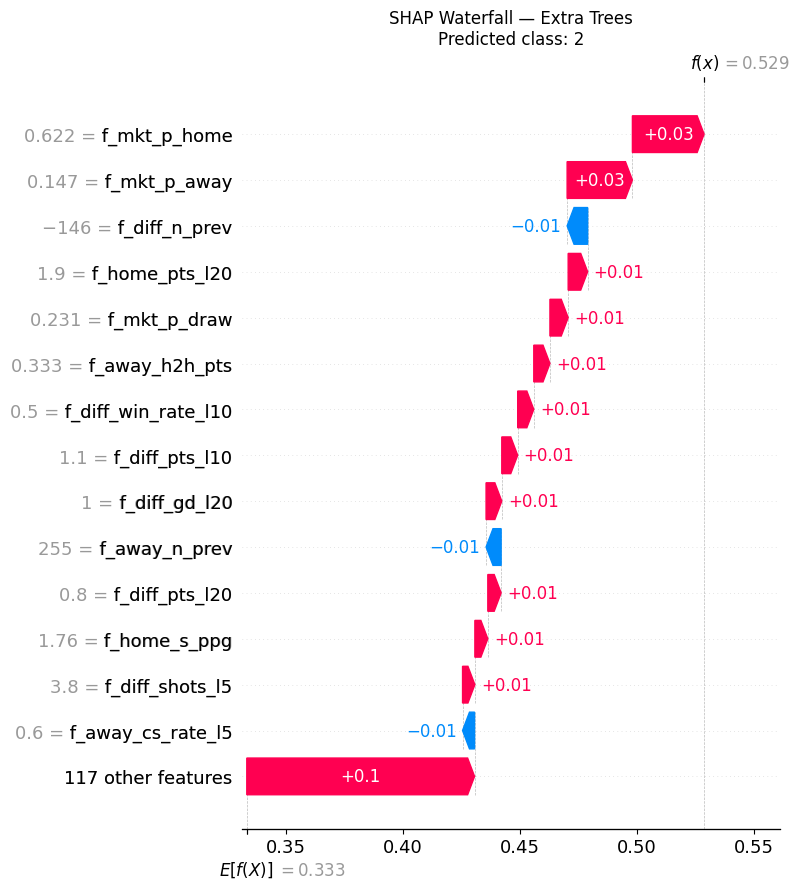

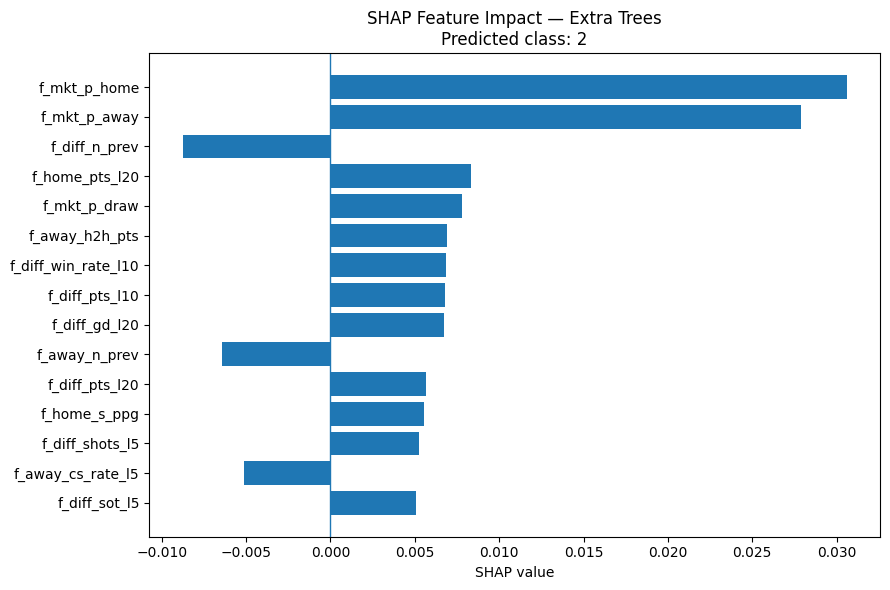

Phương pháp: TreeExplainer
Lớp được giải thích: 2
Top features theo |SHAP|:


,feature,feature_value,shap_value,abs_shap_value
118,f_mkt_p_home,0.62166,0.03060,0.03060
120,f_mkt_p_away,0.14713,0.02787,0.02787
2,f_diff_n_prev,-146.00000,-0.00877,0.00877
66,f_home_pts_l20,1.90000,0.00832,0.00832
119,f_mkt_p_draw,0.23121,0.00778,0.00778
98,f_away_h2h_pts,0.33333,0.00690,0.00690
65,f_diff_win_rate_l10,0.50000,0.00687,0.00687
56,f_diff_pts_l10,1.10000,0.00679,0.00679
71,f_diff_gd_l20,1.00000,0.00671,0.00671
1,f_away_n_prev,255.00000,-0.00643,0.00643



SHAP: HistGradientBoosting


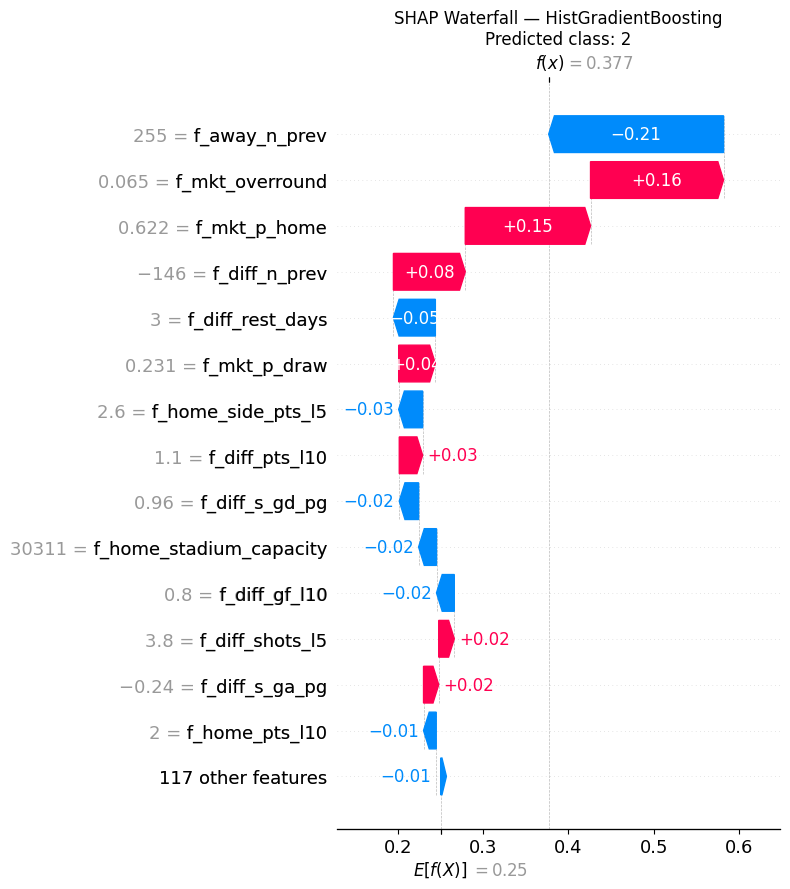

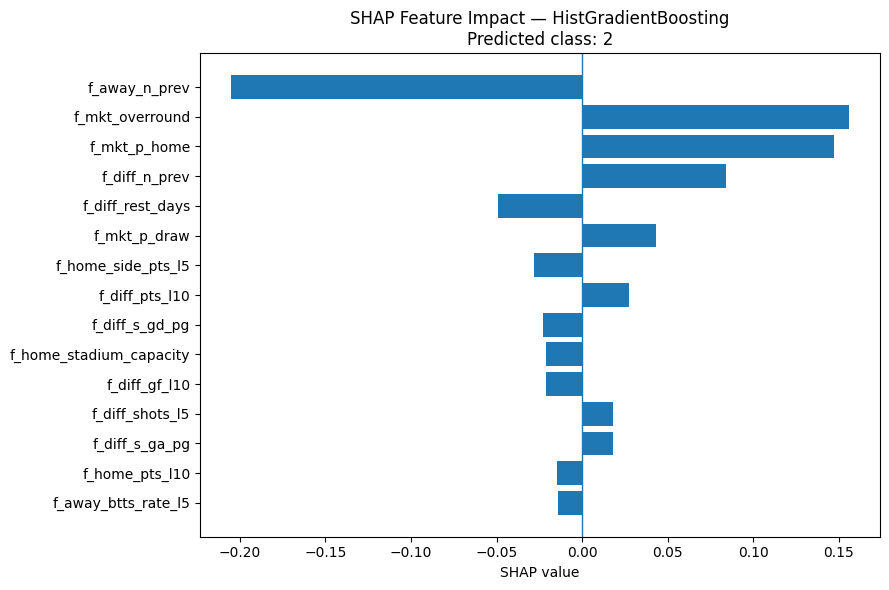

Phương pháp: TreeExplainer
Lớp được giải thích: 2
Top features theo |SHAP|:


,feature,feature_value,shap_value,abs_shap_value
1,f_away_n_prev,255.00000,-0.20507,0.20507
121,f_mkt_overround,0.06530,0.15601,0.15601
118,f_mkt_p_home,0.62166,0.14693,0.14693
2,f_diff_n_prev,-146.00000,0.08425,0.08425
108,f_diff_rest_days,3.00000,-0.04918,0.04918
119,f_mkt_p_draw,0.23121,0.04301,0.04301
72,f_home_side_pts_l5,2.60000,-0.02808,0.02808
56,f_diff_pts_l10,1.10000,0.02741,0.02741
95,f_diff_s_gd_pg,0.96000,-0.02268,0.02268
127,f_home_stadium_capacity,30311.00000,-0.02099,0.02099



SHAP: MLP Neural Network


  0%|          | 0/1 [00:00<?, ?it/s]

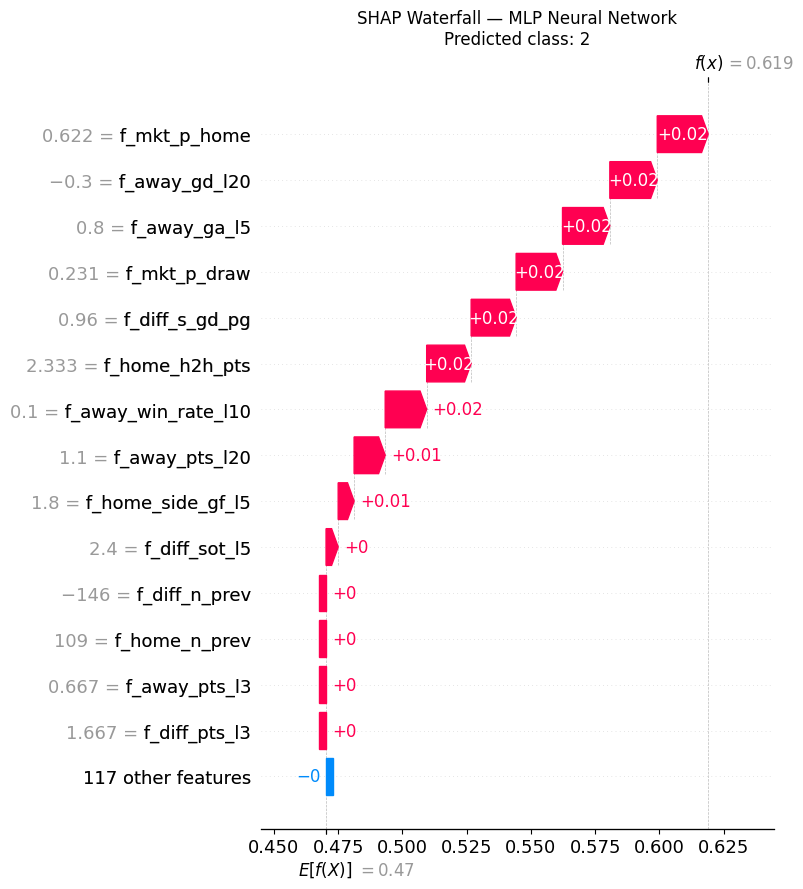

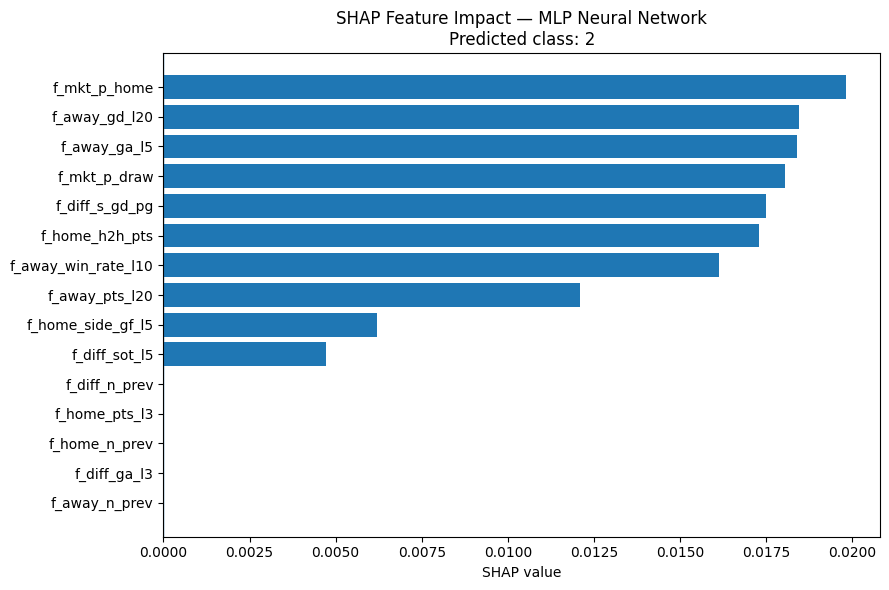

Phương pháp: KernelExplainer
Lớp được giải thích: 2
Top features theo |SHAP|:


,feature,feature_value,shap_value,abs_shap_value
118,f_mkt_p_home,0.62166,0.01982,0.01982
70,f_away_gd_l20,-0.30000,0.01845,0.01845
19,f_away_ga_l5,0.80000,0.01841,0.01841
119,f_mkt_p_draw,0.23121,0.01804,0.01804
95,f_diff_s_gd_pg,0.96000,0.01750,0.01750
97,f_home_h2h_pts,2.33333,0.01730,0.01730
64,f_away_win_rate_l10,0.10000,0.01614,0.01614
67,f_away_pts_l20,1.10000,0.01209,0.01209
75,f_home_side_gf_l5,1.80000,0.00620,0.00620
41,f_diff_sot_l5,2.40000,0.00471,0.00471



TỔNG HỢP SHAP TỪNG MÔ HÌNH


,model,method,predicted_class,base_value,mean_abs_shap,top_feature,top_feature_shap,status
0,XGBoost (đã train),TreeExplainer,2,0.271745,0.004913,f_mkt_p_home,0.210009,success
1,Random Forest,TreeExplainer,2,0.333333,0.002556,f_mkt_p_away,0.040978,success
2,Extra Trees,TreeExplainer,2,0.333333,0.002247,f_mkt_p_home,0.030602,success
3,HistGradientBoosting,TreeExplainer,2,0.250196,0.008436,f_away_n_prev,-0.205067,success
4,MLP Neural Network,KernelExplainer,2,0.470300,0.001135,f_mkt_p_home,0.019820,success


MLflow Run ID: 2c1cef80408e44fb87cbcf1cb64493d3
Artifacts: shap/<tên_mô_hình>/
🏃 View run Football_Model_Comparison_SHAP at: http://100.116.34.36:8080/#/experiments/4/runs/2c1cef80408e44fb87cbcf1cb64493d3
🧪 View experiment at: http://100.116.34.36:8080/#/experiments/4


In [18]:
# ============================================================
# SHAP CHO TỪNG MÔ HÌNH - COLAB + MLFLOW
# Yêu cầu cell so sánh đã tạo fitted_models, Xtr_lime,
# Xte_lime, Xte, FEATURES, CLASSES và aligned_proba.
# ============================================================

import os
import sys
import subprocess
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mlflow

try:
    import shap
except ImportError:
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "-q", "shap"]
    )
    import shap

from IPython.display import display

assert "fitted_models" in globals(), (
    "Chưa có fitted_models. Hãy chạy cell so sánh mô hình trước."
)
assert len(fitted_models) > 0, "Không có mô hình đã train thành công."

# -----------------------------
# CẤU HÌNH
# -----------------------------
TEST_ROW_POSITION = 0       # Dòng test muốn giải thích
BACKGROUND_SIZE = 50        # Nền cho SHAP
KERNEL_NSAMPLES = 100       # Số mẫu xấp xỉ cho mô hình không phải cây
MAX_DISPLAY = min(15, len(FEATURES))

OUTPUT_DIR = "model_comparison_artifacts/shap"
os.makedirs(OUTPUT_DIR, exist_ok=True)

if TEST_ROW_POSITION < 0 or TEST_ROW_POSITION >= len(Xte_lime):
    raise IndexError("TEST_ROW_POSITION nằm ngoài phạm vi dữ liệu test.")

# Chọn background từ train, dùng chung cho mọi mô hình
rng = np.random.default_rng(42)
n_background = min(BACKGROUND_SIZE, len(Xtr_lime))
background_idx = rng.choice(
    len(Xtr_lime), size=n_background, replace=False
)

X_background = Xtr_lime.iloc[background_idx].copy()
X_instance = Xte_lime.iloc[[TEST_ROW_POSITION]].copy()

# SHAP sử dụng dữ liệu đã điền giá trị thiếu
X_background.columns = [str(c) for c in FEATURES]
X_instance.columns = [str(c) for c in FEATURES]

print("SHAP version:", shap.__version__)
print("Test row:", Xte.index[TEST_ROW_POSITION])
print("Số mô hình:", len(fitted_models))

# Dùng run hiện tại nếu còn mở, nếu không mở run bổ sung
started_new_run = mlflow.active_run() is None

if started_new_run:
    shap_run = mlflow.start_run(
        run_name="Football_Model_Comparison_SHAP"
    )
else:
    shap_run = mlflow.active_run()

shap_run_id = shap_run.info.run_id
shap_summary_rows = []


def get_final_estimator(estimator):
    """Lấy estimator cuối trong sklearn Pipeline nếu có."""
    if hasattr(estimator, "steps"):
        return estimator.steps[-1][1]
    return estimator


def is_tree_model(estimator):
    """Nhận diện mô hình cây có thể dùng TreeExplainer."""
    final_estimator = get_final_estimator(estimator)
    tree_names = (
        "XGBClassifier",
        "XGBRegressor",
        "RandomForestClassifier",
        "ExtraTreesClassifier",
        "HistGradientBoostingClassifier",
        "DecisionTreeClassifier",
        "GradientBoostingClassifier",
        "RandomForestRegressor",
        "ExtraTreesRegressor",
    )
    return (
        final_estimator.__class__.__name__ in tree_names
        or "XGB" in final_estimator.__class__.__name__
    )


def normalize_shap_values(values, class_position, n_features):
    """
    Chuẩn hóa kết quả SHAP nhiều lớp thành vector
    có độ dài bằng số features.
    """
    if isinstance(values, list):
        # API cũ: list gồm một ma trận cho mỗi lớp
        arr = np.asarray(values[class_position])
    else:
        arr = np.asarray(values)

        # API mới: (samples, features, classes)
        if arr.ndim == 3:
            if arr.shape[-1] == len(CLASSES):
                arr = arr[:, :, class_position]
            elif arr.shape[1] == len(CLASSES):
                arr = arr[:, class_position, :]
            else:
                arr = arr[:, :, 0]

        # (samples, features)
        elif arr.ndim == 2:
            pass

        # (features,)
        elif arr.ndim == 1:
            arr = arr.reshape(1, -1)

    arr = np.asarray(arr)

    if arr.ndim == 2:
        arr = arr[0]

    arr = arr.reshape(-1)

    if len(arr) != n_features:
        raise ValueError(
            f"SHAP trả về {len(arr)} giá trị, "
            f"nhưng có {n_features} features."
        )

    return arr.astype(float)


try:
    for model_name, estimator in fitted_models.items():
        print("\n" + "=" * 70)
        print("SHAP:", model_name)
        print("=" * 70)

        slug = safe_name(model_name)
        model_dir = os.path.join(OUTPUT_DIR, slug)
        os.makedirs(model_dir, exist_ok=True)

        try:
            # Lấy lớp dự đoán để giải thích
            predicted_class = int(
                estimator.predict(Xte.iloc[[TEST_ROW_POSITION]])[0]
            )
            class_matches = np.flatnonzero(CLASSES == predicted_class)

            if len(class_matches) == 0:
                raise ValueError(
                    f"Lớp dự đoán {predicted_class} không nằm trong CLASSES."
                )

            class_position = int(class_matches[0])

            # ------------------------------------------------
            # 1. TREE SHAP CHO MÔ HÌNH CÂY
            # ------------------------------------------------
            if is_tree_model(estimator):
                tree_model = get_final_estimator(estimator)

                # Dùng TreeExplainer trên estimator cuối.
                # Dữ liệu đầu vào đã được điền missing value.
                explainer = shap.TreeExplainer(tree_model)

                with warnings.catch_warnings():
                    warnings.simplefilter("ignore")
                    raw_shap = explainer.shap_values(
                        X_instance,
                        check_additivity=False,
                    )

                shap_vector = normalize_shap_values(
                    raw_shap,
                    class_position,
                    len(FEATURES),
                )

                # Base value tương ứng lớp đang giải thích
                base_values = explainer.expected_value
                base_arr = np.asarray(base_values)

                if base_arr.ndim == 0:
                    base_value = float(base_arr)
                elif base_arr.size == len(CLASSES):
                    base_value = float(base_arr.reshape(-1)[class_position])
                else:
                    base_value = float(base_arr.reshape(-1)[0])

                method_name = "TreeExplainer"

            # ------------------------------------------------
            # 2. KERNEL SHAP CHO MLP / MODEL KHÔNG PHẢI CÂY
            # ------------------------------------------------
            else:
                def predict_proba_for_shap(data):
                    frame = pd.DataFrame(
                        np.asarray(data),
                        columns=FEATURES,
                    )
                    return aligned_proba(estimator, frame)

                explainer = shap.KernelExplainer(
                    predict_proba_for_shap,
                    X_background.to_numpy(dtype=float),
                )

                with warnings.catch_warnings():
                    warnings.simplefilter("ignore")
                    raw_shap = explainer.shap_values(
                        X_instance.to_numpy(dtype=float),
                        nsamples=KERNEL_NSAMPLES,
                    )

                shap_vector = normalize_shap_values(
                    raw_shap,
                    class_position,
                    len(FEATURES),
                )

                base_values = explainer.expected_value
                base_arr = np.asarray(base_values)

                if base_arr.ndim == 0:
                    base_value = float(base_arr)
                else:
                    base_value = float(base_arr.reshape(-1)[class_position])

                method_name = "KernelExplainer"

            # ------------------------------------------------
            # 3. LƯU GIÁ TRỊ SHAP
            # ------------------------------------------------
            values_df = pd.DataFrame({
                "feature": FEATURES,
                "feature_value": X_instance.iloc[0].to_numpy(),
                "shap_value": shap_vector,
                "abs_shap_value": np.abs(shap_vector),
            }).sort_values(
                "abs_shap_value",
                ascending=False,
            )

            csv_path = os.path.join(
                model_dir,
                f"shap_values_test_row_{TEST_ROW_POSITION}.csv",
            )
            values_df.to_csv(csv_path, index=False)

            # ------------------------------------------------
            # 4. WATERFALL PLOT: GIẢI THÍCH DỰ ĐOÁN CỤ THỂ
            # ------------------------------------------------
            explanation = shap.Explanation(
                values=shap_vector,
                base_values=base_value,
                data=X_instance.iloc[0].to_numpy(dtype=float),
                feature_names=[str(c) for c in FEATURES],
            )

            plt.figure()
            shap.plots.waterfall(
                explanation,
                max_display=MAX_DISPLAY,
                show=False,
            )
            plt.title(
                f"SHAP Waterfall — {model_name}\n"
                f"Predicted class: {predicted_class}"
            )
            plt.tight_layout()

            waterfall_path = os.path.join(
                model_dir,
                f"shap_waterfall_test_row_{TEST_ROW_POSITION}.png",
            )
            plt.savefig(
                waterfall_path,
                dpi=160,
                bbox_inches="tight",
            )
            plt.show()
            plt.close()

            # ------------------------------------------------
            # 5. BAR PLOT: FEATURES ẢNH HƯỞNG MẠNH NHẤT
            # ------------------------------------------------
            top_features = values_df.head(MAX_DISPLAY).sort_values(
                "abs_shap_value",
                ascending=True,
            )

            plt.figure(figsize=(9, 6))
            plt.barh(
                top_features["feature"].astype(str),
                top_features["shap_value"],
            )
            plt.axvline(0, linewidth=1)
            plt.xlabel("SHAP value")
            plt.title(
                f"SHAP Feature Impact — {model_name}\n"
                f"Predicted class: {predicted_class}"
            )
            plt.tight_layout()

            bar_path = os.path.join(
                model_dir,
                f"shap_feature_impact_test_row_{TEST_ROW_POSITION}.png",
            )
            plt.savefig(bar_path, dpi=160, bbox_inches="tight")
            plt.show()
            plt.close()

            # ------------------------------------------------
            # 6. LOG VÀO MLflow
            # ------------------------------------------------
            mlflow.log_artifact(
                csv_path,
                artifact_path=f"shap/{slug}",
            )
            mlflow.log_artifact(
                waterfall_path,
                artifact_path=f"shap/{slug}",
            )
            mlflow.log_artifact(
                bar_path,
                artifact_path=f"shap/{slug}",
            )

            mlflow.log_metric(
                f"{slug}_shap_mean_abs_value",
                float(np.mean(np.abs(shap_vector))),
            )
            mlflow.set_tag(f"{slug}_shap_method", method_name)
            mlflow.set_tag(f"{slug}_shap_status", "success")

            shap_summary_rows.append({
                "model": model_name,
                "method": method_name,
                "predicted_class": predicted_class,
                "base_value": base_value,
                "mean_abs_shap": float(
                    np.mean(np.abs(shap_vector))
                ),
                "top_feature": str(values_df.iloc[0]["feature"]),
                "top_feature_shap": float(
                    values_df.iloc[0]["shap_value"]
                ),
                "status": "success",
            })

            print("Phương pháp:", method_name)
            print("Lớp được giải thích:", predicted_class)
            print("Top features theo |SHAP|:")
            display(values_df.head(MAX_DISPLAY).round(5))

        except Exception as e:
            error_msg = f"{type(e).__name__}: {str(e)}"
            print("Không tạo được SHAP:", error_msg)

            mlflow.set_tag(
                f"{slug}_shap_status",
                f"failed_{type(e).__name__}",
            )

            shap_summary_rows.append({
                "model": model_name,
                "method": None,
                "predicted_class": None,
                "base_value": None,
                "mean_abs_shap": None,
                "top_feature": None,
                "top_feature_shap": None,
                "status": error_msg[:250],
            })

    # --------------------------------------------------------
    # 7. BẢNG TỔNG HỢP SHAP
    # --------------------------------------------------------
    shap_summary = pd.DataFrame(shap_summary_rows)

    print("\n" + "=" * 70)
    print("TỔNG HỢP SHAP TỪNG MÔ HÌNH")
    print("=" * 70)
    display(shap_summary)

    summary_path = os.path.join(
        OUTPUT_DIR,
        f"shap_summary_test_row_{TEST_ROW_POSITION}.csv",
    )
    shap_summary.to_csv(summary_path, index=False)

    mlflow.log_artifact(
        summary_path,
        artifact_path="shap/summary",
    )

    print("MLflow Run ID:", shap_run_id)
    print("Artifacts: shap/<tên_mô_hình>/")

finally:
    if started_new_run and mlflow.active_run() is not None:
        mlflow.end_run()